# Opdracht 1: Voorspel herseninfarct

**Teamnaam: 6** 

Aroetin Avanesi

Moreo Rahiembaks

Kaylim Taai

## Inhoudsopgave
1. Inleiding
2. Exploratieve Data Analyse
3. Evaluatie
4. Modellen
5. Conclusie en advies
6. Referenties

## 1. Inleiding

MedPredict is een medisch technologiebedrijf dat zorginstellingen en ziekenhuizen helpt om gezondheidsrisico's vroeg te herkennen. Het bedrijf heeft geanonimiseerde patiëntgegevens met demografische kenmerken, leefstijl en medische informatie.

Ongeveer 90% van de herseninfarcten hangt samen met risicofactoren die vooraf te meten en te beïnvloeden zijn, zoals hoge bloeddruk, roken en diabetes (O'Donnell et al., 2016). Als je patiënten met een verhoogd risico op tijd kunt herkennen, zijn artsen in staat om eerder in te grijpen met preventieve maatregelen.

Ons team bestaande uit junior data scientists is gevraagd om een machine learning model te bouwen dat dit risico voorspelt. MedPredict vergelijkt de oplossingen van verschillende teams via een interne Kaggle competitie.

### 1.1 Probleemstelling

MedPredict wil een model dat:
* op basis van patiëntgegevens voorspelt of iemand een herseninfarct kan krijgen
* zo min mogelijk patiënten met een verhoogd risico mist, maar ook zo min mogelijk valse alarmen geeft
* betrouwbaar en duidelijk genoeg is om artsen te ondersteunen

Omdat we hier te maken hebben met een medische toepassing, kunnen fouten leiden tot echte gevolgen. Een gemiste patiënt zou bijvoorbeeld geen preventie krijgen, terwijl een vals alarm iemand onnodige zorgen en lasten kan geven. Daarom kijken we niet alleen naar de score, maar ook naar de keuzes die we maken en beoordelen we hoe betrouwbaar het model is.

## 2. Exploratieve Data Analyse

### 2.1 Data inladen

In [38]:
from pathlib import Path

import pandas as pd


class StrokeData:
    """Laadt de datasets van de Kaggle competitie Predicting stroke."""

    def __init__(self, data_dir="data"):
        # Map waarin de csv bestanden staan
        self.data_dir = Path(data_dir)
        self.train = None
        self.test = None
        self.submission = None

    def load(self):
        """Leest alle drie de csv bestanden in als DataFrames."""
        self.train = pd.read_csv(self.data_dir / "train.csv")
        self.test = pd.read_csv(self.data_dir / "test.csv")
        self.submission = pd.read_csv(
            self.data_dir / "sample_submission.csv"
        )
        return self

    def check_shapes(self):
        """Toont het aantal rijen en kolommen van iedere dataset."""
        print(f"train:      {self.train.shape}")
        print(f"test:       {self.test.shape}")
        print(f"submission: {self.submission.shape}")


data = StrokeData().load()
data.check_shapes()
data.train.head()

train:      (33550, 22)
test:       (8388, 21)
submission: (8388, 2)


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,False,True,False,True,...,False,True,False,False,True,False,False,False,True,0
1,72295,75.0,1,0,215.17,48.0,True,False,False,False,...,False,False,True,False,True,False,False,True,False,0
2,26451,15.0,0,0,135.22,19.0,False,True,False,True,...,False,True,False,False,True,False,False,True,False,0
3,65210,47.0,0,0,64.89,28.2,False,True,False,False,...,False,False,True,False,False,True,False,True,False,0
4,69299,49.0,0,0,222.34,28.8,False,True,False,False,...,False,False,True,False,True,False,True,False,False,0


### 2.2 Uitleg kolommen

De dataset bevat 33.550 patiënten en 22 kolommen. De originele categorische kolommen (zoals geslacht en soort werk) zijn al door Kaggle omgezet naar **dummy-kolommen**: voor iedere categorie is er een aparte kolom met `True` of `False`. Per patiënt staat binnen een groep precies één kolom op `True`, behalve bij roken (zie hieronder).

| Kolom | Soort | Uitleg |
|---|---|---|
| `id` | identificatie | Uniek nummer per patiënt. Bevat geen medische informatie en is alleen nodig om voorspellingen aan de juiste patiënt te koppelen bij de Kaggle-inlevering. |
| `age` | numeriek | Leeftijd in jaren, van 0,08 (een baby van ongeveer 1 maand) tot 82 jaar. Bij kinderen onder de 2 jaar is de leeftijd een kommagetal. |
| `hypertension` | binair (0/1) | 1 = de patiënt heeft hoge bloeddruk (hypertensie), 0 = niet. |
| `heart_disease` | binair (0/1) | 1 = de patiënt heeft een hartziekte, 0 = niet. |
| `avg_glucose_level` | numeriek | Gemiddeld suikergehalte (glucose) in het bloed in mg/dL, van 55 tot 282. Een hoge waarde kan wijzen op diabetes. |
| `bmi` | numeriek | Body Mass Index: gewicht (kg) gedeeld door lengte in het kwadraat (m²), van 10,1 tot 97,6. Tussen 18,5 en 25 geldt als gezond, boven 30 als obesitas. |
| `gender_Female`, `gender_Male`, `gender_Other` | dummy (True/False) | Geslacht van de patiënt: vrouw, man of anders. `gender_Other` komt maar 6 keer voor. |
| `ever_married_No`, `ever_married_Yes` | dummy (True/False) | Of de patiënt ooit getrouwd is geweest. |
| `work_type_Govt_job`, `work_type_Never_worked`, `work_type_Private`, `work_type_Self-employed`, `work_type_children` | dummy (True/False) | Soort werk: bij de overheid, nooit gewerkt, in de private sector, zelfstandige, of kind (werkt nog niet). |
| `Residence_type_Rural`, `Residence_type_Urban` | dummy (True/False) | Woonomgeving: platteland (rural) of stad (urban). |
| `smoking_status_formerly smoked`, `smoking_status_never smoked`, `smoking_status_smokes` | dummy (True/False) | Rookgedrag: vroeger gerookt, nooit gerookt of rookt. Als alle drie de kolommen `False` zijn, is de rookstatus onbekend. Dat geldt voor 10.320 patiënten (31%). |
| `stroke` | binair (0/1) | **Doelvariabele (y).** 1 = de patiënt heeft een herseninfarct gehad, 0 = niet. Deze kolom gaan we voorspellen. |

`stroke` is de afhankelijke variabele. Alle andere kolommen behalve `id` zijn onafhankelijke variabelen (features) die we gebruiken om `stroke` te voorspellen.

In [39]:
def describe_columns(df):
    """Datatype, aantal unieke waarden, bereik en voorbeelden per kolom."""
    return pd.DataFrame({
        "datatype": df.dtypes.astype(str),
        "uniek": df.nunique(),
        "min": df.min(),
        "max": df.max(),
        "voorbeelden": [df[col].unique()[:5] for col in df.columns],
    })


describe_columns(data.train)

,datatype,uniek,min,max,voorbeelden
id,int64,33550,1,72943,"[52709, 72295, 26451, 65210, 69299]"
age,float64,104,0.08,82.0,"[30.0, 75.0, 15.0, 47.0, 49.0]"
hypertension,int64,2,0,1,"[0, 1]"
heart_disease,int64,2,0,1,"[0, 1]"
avg_glucose_level,float64,11241,55.01,281.59,"[63.6, 215.17, 135.22, 64.89, 222.34]"
bmi,float64,542,10.1,97.6,"[33.3, 48.0, 19.0, 28.2, 28.8]"
gender_Female,bool,2,False,True,"[False, True]"
gender_Male,bool,2,False,True,"[True, False]"
gender_Other,bool,2,False,True,"[False, True]"
ever_married_No,bool,2,False,True,"[True, False]"


In [40]:
def count_true_per_row(df, columns):
    """Telt per rij hoeveel van de opgegeven dummy-kolommen True zijn."""
    # True telt als 1, False als 0
    return df[columns].sum(axis=1).value_counts()


smoking_cols = ["smoking_status_formerly smoked",
                "smoking_status_never smoked",
                "smoking_status_smokes"]
count_true_per_row(data.train, smoking_cols)

1    23230
0    10320
Name: count, dtype: int64

### 2.3 Datatypes en basisstatistieken

In [41]:
NUMERIC_COLS = ["age", "avg_glucose_level", "bmi"]
BINARY_COLS = ["hypertension", "heart_disease"]
TARGET = "stroke"


def show_overview(df):
    """Toont het formaat, ontbrekende waarden en dubbele rijen."""
    print(f"Aantal rijen: {df.shape[0]}, aantal kolommen: {df.shape[1]}")
    print(f"Ontbrekende waarden in totaal: {df.isna().sum().sum()}")
    # id laten we weg, anders is iedere rij uniek
    print(f"Dubbele rijen: {df.drop(columns='id').duplicated().sum()}")
    print("\nAantal kolommen per datatype:")
    print(df.dtypes.value_counts())


show_overview(data.train)
data.train.dtypes

Aantal rijen: 33550, aantal kolommen: 22
Ontbrekende waarden in totaal: 0
Dubbele rijen: 0

Aantal kolommen per datatype:
bool       15
int64       4
float64     3
Name: count, dtype: int64


id                                  int64
age                               float64
hypertension                        int64
heart_disease                       int64
avg_glucose_level                 float64
bmi                               float64
gender_Female                        bool
gender_Male                          bool
gender_Other                         bool
ever_married_No                      bool
ever_married_Yes                     bool
work_type_Govt_job                   bool
work_type_Never_worked               bool
work_type_Private                    bool
work_type_Self-employed              bool
work_type_children                   bool
Residence_type_Rural                 bool
Residence_type_Urban                 bool
smoking_status_formerly smoked       bool
smoking_status_never smoked          bool
smoking_status_smokes                bool
stroke                              int64
dtype: object

In [42]:
# Gemiddelde, spreiding, minimum, kwartielen en maximum
data.train[NUMERIC_COLS].describe().round(2)

,age,avg_glucose_level,bmi
count,33550.00,33550.00,33550.00
mean,41.82,103.59,28.60
std,22.48,42.13,7.78
min,0.08,55.01,10.10
25%,24.00,77.46,23.30
50%,43.00,91.32,27.70
75%,59.00,111.44,32.80
max,82.00,281.59,97.60


In [43]:
def percentage_true(df, columns):
    """Aantal en percentage patiënten met waarde 1/True per kolom."""
    return pd.DataFrame({
        "aantal": df[columns].sum(),
        "percentage": (df[columns].mean() * 100).round(2),
    })


dummy_cols = data.train.select_dtypes(include="bool").columns.tolist()
percentage_true(data.train, BINARY_COLS + dummy_cols + [TARGET])

,aantal,percentage
hypertension,2957,8.81
heart_disease,1444,4.30
gender_Female,20032,59.71
gender_Male,13512,40.27
gender_Other,6,0.02
ever_married_No,12124,36.14
ever_married_Yes,21426,63.86
work_type_Govt_job,4156,12.39
work_type_Never_worked,141,0.42
work_type_Private,19279,57.46


**Datatypes.** De dataset heeft 33.550 rijen en 22 kolommen. Daarvan zijn er 15 dummy-kolommen (`bool`), 4 gehele getallen (`int64`: `id`, `hypertension`, `heart_disease` en `stroke`) en 3 kommagetallen (`float64`: `age`, `avg_glucose_level` en `bmi`). Er ontbreken geen waarden en er zijn geen dubbele rijen.

**Numerieke kolommen.**
* `age`: Het gemiddelde (41,8) en de mediaan (43) liggen dicht bij elkaar, dus de verdeling is ongeveer symmetrisch.
* `avg_glucose_level`: het gemiddelde is 103,6, maar de mediaan is 91,3. Het gemiddelde ligt hoger doordat een deel van de patiënten een veel hogere waarde heeft (maximum 281,6). De verdeling is dus scheef naar rechts.
* `bmi`: het gemiddelde is 28,6 en de waarden lopen van 10,1 tot 97,6. Een BMI van 97,6 is extreem hoog. Of dit een fout of een echte uitschieter is, bekijken we bij de outliers in 2.5.
* De schalen verschillen sterk (`age` gaat tot 82, `avg_glucose_level` tot 282). Daarom moeten we de kolommen later nog standaardiseren (2.8).

**Binaire en dummy-kolommen.**
* Maar 1,54% van de patiënten heeft een stroke gehad (517 van de 33.550). De data is dus sterk imbalanced.
* 8,81% heeft hypertension (hoge bloeddruk) en 4,30% heeft een hartziekte.
* `gender_Other` komt maar 6 keer voor (0,02%) en `work_type_Never_worked` 141 keer (0,42%). Dat zijn hele kleine groepen.
* Stad en platteland zijn bijna precies even groot (16.774 tegen 16.776, beide 50,00%).

### 2.4 Voldoet de data aan de eisen van Scikit-Learn?

In [44]:
import numpy as np


def check_sklearn_ready(X, y):
    """Controleert of X en y voldoen aan de eisen van scikit-learn."""
    text_cols = X.select_dtypes(include="object").columns.tolist()
    print("Geen tekstkolommen:      ", len(text_cols) == 0)
    print("Geen ontbrekende waarden:", X.isna().sum().sum() == 0)
    print("Geen oneindige waarden:  ", not np.isinf(X.astype(float)).any().any())
    print("X is een tabel (2D):     ", X.ndim == 2)
    print("y is één kolom (1D):     ", y.ndim == 1)
    print("X en y even lang:        ", len(X) == len(y))


# X = de features, y = wat we willen voorspellen
X = data.train.drop(columns=["id", TARGET])
y = data.train[TARGET]
check_sklearn_ready(X, y)

Geen tekstkolommen:       True
Geen ontbrekende waarden: True
Geen oneindige waarden:   True
X is een tabel (2D):      True
y is één kolom (1D):      True
X en y even lang:         True


Om een model te kunnen trainen met scikit-learn moet de data aan een paar minimale eisen voldoen:

1. **Alles is numeriek.** Een model rekent met getallen, niet met tekst zoals "Male" of "Urban".
2. **Geen ontbrekende waarden.** De meeste modellen geven een foutmelding bij lege cellen (`NaN`).
3. **Geen oneindige waarden** (`inf`).
4. **De juiste vorm.** X (de features) is een tabel met rijen en kolommen, y (de doelvariabele) is één kolom, en ze hebben evenveel rijen.

Onze data voldoet al aan deze eisen. Kaggle heeft de tekstkolommen al omgezet naar dummy-kolommen (`True`/`False`), en scikit-learn rekent `True` als 1 en `False` als 0. Er zijn geen ontbrekende of oneindige waarden.

Wel halen we `id` uit X. Het is een volgnummer zonder medische betekenis, en als we het laten staan kan een model er toevallige patronen in vinden.

### 2.5 Relaties tussen de variabelen en stroke

stroke
0    98.46
1     1.54
Name: proportion, dtype: float64


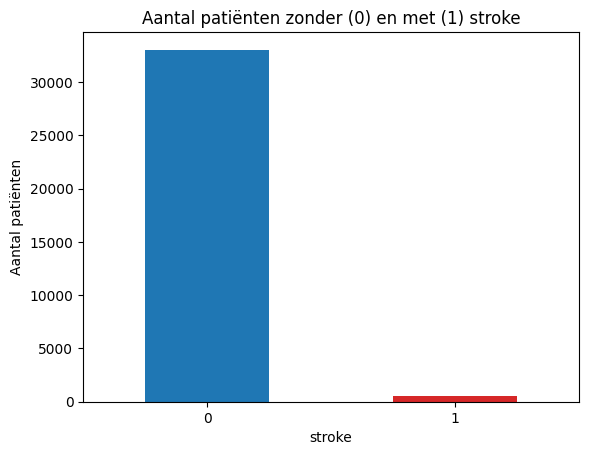

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

counts = data.train[TARGET].value_counts()
print((data.train[TARGET].value_counts(normalize=True) * 100).round(2))

counts.plot(kind="bar", color=["tab:blue", "tab:red"])
plt.title("Aantal patiënten zonder (0) en met (1) stroke")
plt.xlabel("stroke")
plt.ylabel("Aantal patiënten")
plt.xticks(rotation=0)
plt.show()

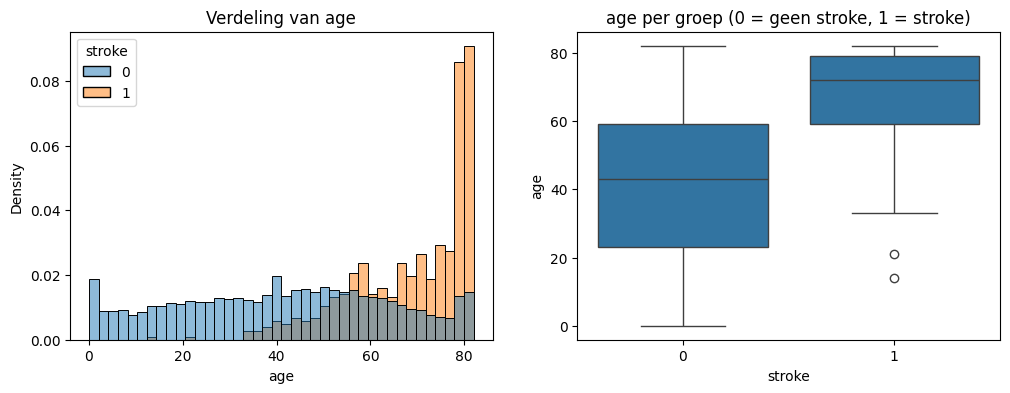

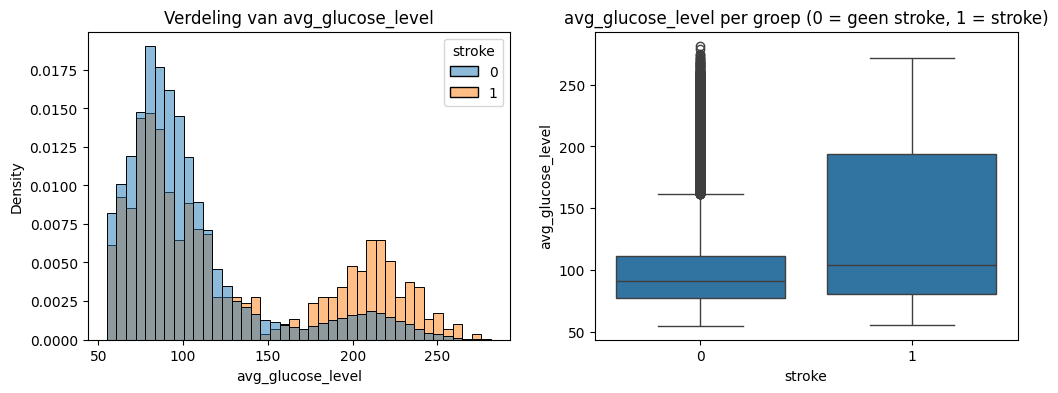

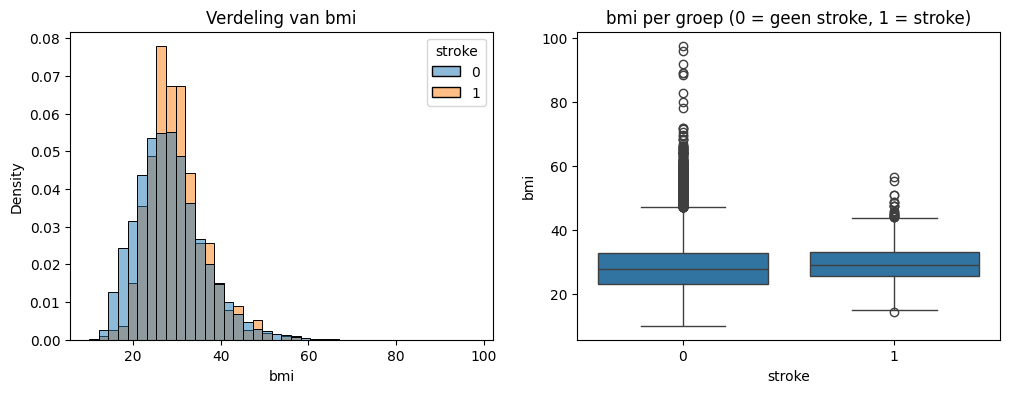

,age,avg_glucose_level,bmi
stroke,,,
0,43.0,91.22,27.7
1,72.0,104.12,29.0


In [46]:
def plot_numeric_by_target(df, columns, target):
    """Histogram en boxplot per numerieke kolom, gesplitst op stroke."""
    for col in columns:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        # common_norm=False: beide groepen even hoog, ook de kleine groep
        sns.histplot(data=df, x=col, hue=target, stat="density",
                     common_norm=False, bins=40, ax=axes[0])
        axes[0].set_title(f"Verdeling van {col}")
        sns.boxplot(data=df, x=target, y=col, ax=axes[1])
        axes[1].set_title(f"{col} per groep (0 = geen stroke, 1 = stroke)")
        plt.show()


plot_numeric_by_target(data.train, NUMERIC_COLS, TARGET)
data.train.groupby(TARGET)[NUMERIC_COLS].median()

In [47]:
def count_outliers(df, columns):
    """Telt per kolom de outliers volgens de IQR-regel."""
    rows = []
    for col in columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        # Buiten deze grenzen is een waarde een outlier
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        outliers = df[(df[col] < lower) | (df[col] > upper)]
        rows.append({"kolom": col, "ondergrens": lower,
                     "bovengrens": upper, "aantal outliers": len(outliers),
                     "% stroke bij outliers": outliers[TARGET].mean() * 100})
    return pd.DataFrame(rows).round(2)


count_outliers(data.train, NUMERIC_COLS)

,kolom,ondergrens,bovengrens,aantal outliers,% stroke bij outliers
0,age,-28.50,111.50,0,NaN
1,avg_glucose_level,26.49,162.40,3641,4.48
2,bmi,9.05,47.05,769,1.30


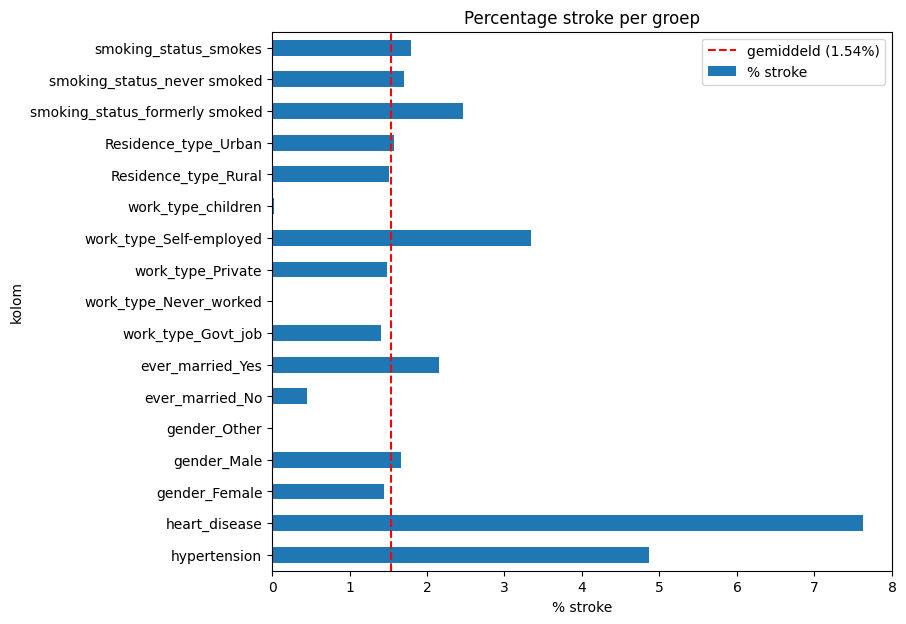

,aantal patiënten,% stroke
kolom,,
hypertension,2957,4.87
heart_disease,1444,7.62
gender_Female,20032,1.45
gender_Male,13512,1.67
gender_Other,6,0.00
ever_married_No,12124,0.45
ever_married_Yes,21426,2.16
work_type_Govt_job,4156,1.40
work_type_Never_worked,141,0.00


In [48]:
def stroke_percentage(df, columns, target):
    """Percentage stroke bij patiënten waarbij de kolom 1/True is."""
    rows = []
    for col in columns:
        group = df[df[col] == 1]
        rows.append({"kolom": col, "aantal patiënten": len(group),
                     "% stroke": group[target].mean() * 100})
    return pd.DataFrame(rows).set_index("kolom").round(2)


dummy_cols = data.train.select_dtypes(include="bool").columns.tolist()
rates = stroke_percentage(data.train, BINARY_COLS + dummy_cols, TARGET)

overall = data.train[TARGET].mean() * 100
rates["% stroke"].plot(kind="barh", figsize=(8, 7))
plt.axvline(overall, color="red", linestyle="--",
            label=f"gemiddeld ({overall:.2f}%)")
plt.title("Percentage stroke per groep")
plt.xlabel("% stroke")
plt.legend()
plt.show()
rates

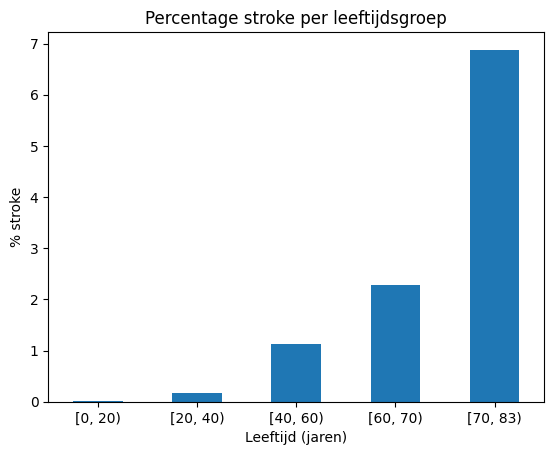

age
[0, 20)     0.01
[20, 40)    0.18
[40, 60)    1.12
[60, 70)    2.28
[70, 83)    6.88
Name: stroke, dtype: float64

In [49]:
age_groups = pd.cut(data.train["age"], bins=[0, 20, 40, 60, 70, 83],
                    right=False)
stroke_by_age = data.train.groupby(age_groups, observed=True)[TARGET].mean()
stroke_by_age = (stroke_by_age * 100).round(2)

stroke_by_age.plot(kind="bar")
plt.title("Percentage stroke per leeftijdsgroep")
plt.xlabel("Leeftijd (jaren)")
plt.ylabel("% stroke")
plt.xticks(rotation=0)
plt.show()
stroke_by_age

In [50]:
smoking_cols = ["smoking_status_formerly smoked",
                "smoking_status_never smoked",
                "smoking_status_smokes"]
# Unknown = alle drie de rookkolommen False
unknown = data.train[smoking_cols].sum(axis=1) == 0
children = data.train["work_type_children"]

print(f"Gemiddelde leeftijd Unknown: "
      f"{data.train.loc[unknown, 'age'].mean():.1f} jaar")
print(f"Kinderen met Unknown: {(unknown & children).sum()} "
      f"van de {children.sum()} kinderen")

Gemiddelde leeftijd Unknown: 28.8 jaar
Kinderen met Unknown: 4343 van de 4848 kinderen


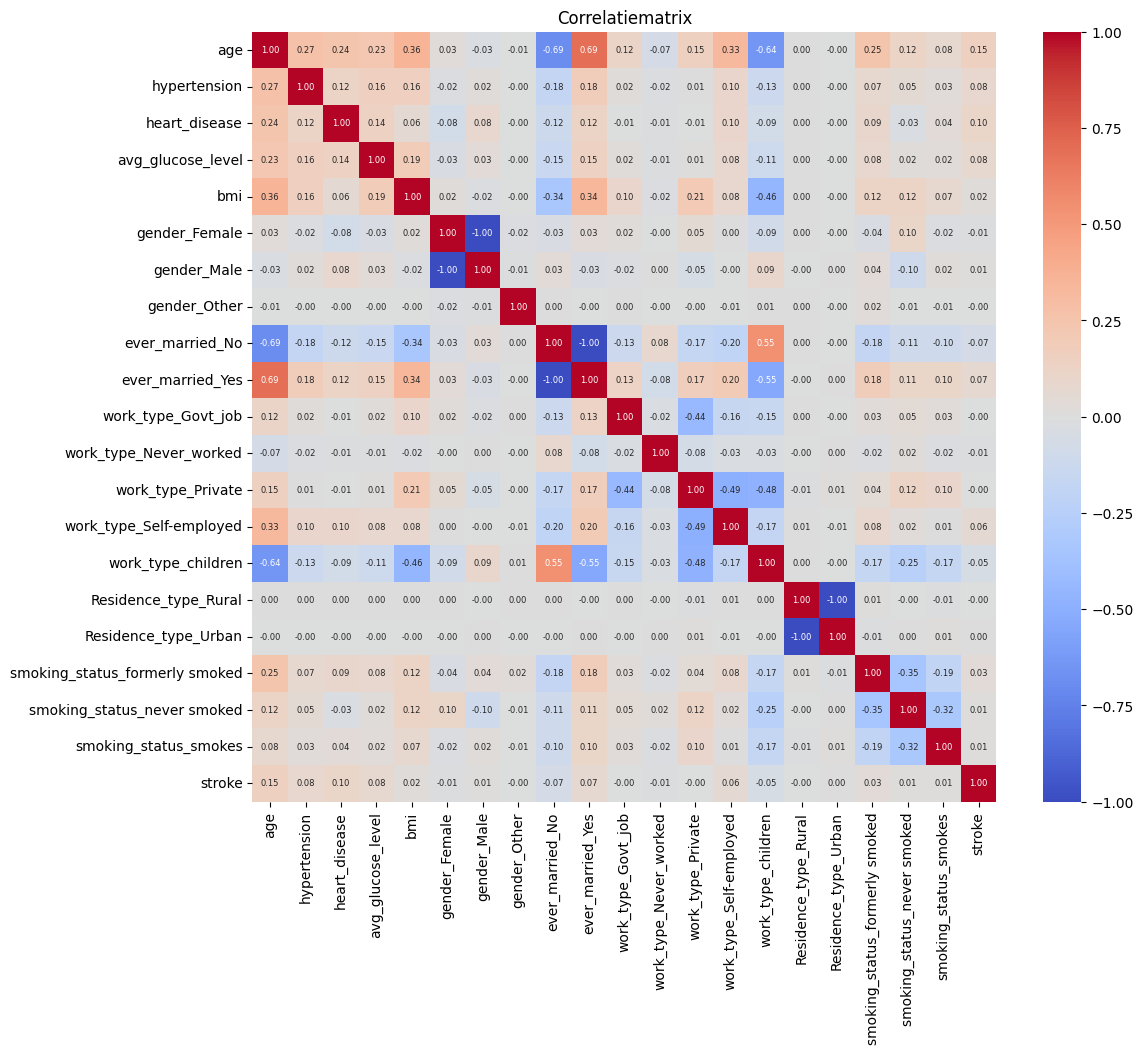

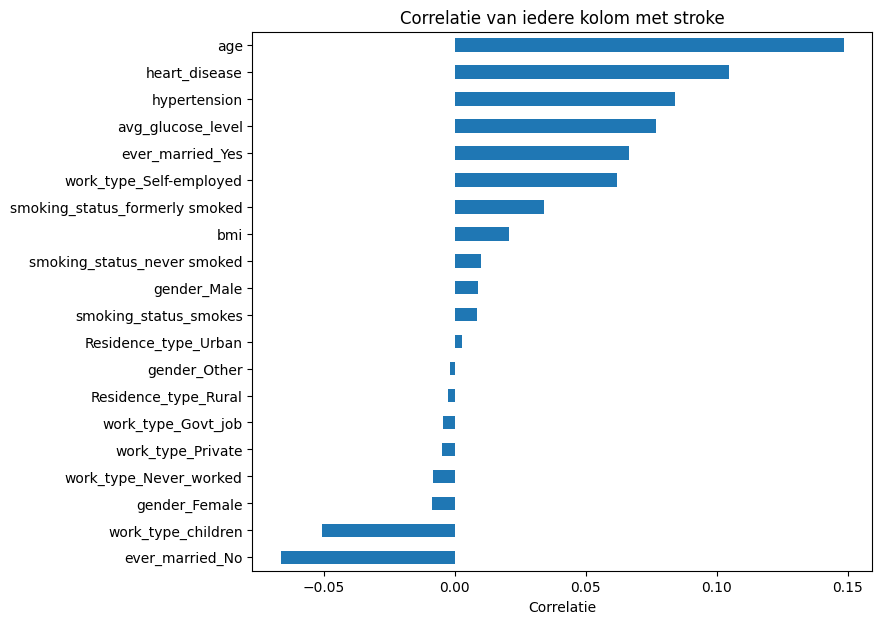

In [51]:
corr = data.train.drop(columns="id").corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 6})
plt.title("Correlatiematrix")
plt.show()

# Alleen de correlatie met stroke, gesorteerd
target_corr = corr[TARGET].drop(TARGET).sort_values()
target_corr.plot(kind="barh", figsize=(8, 7))
plt.title("Correlatie van iedere kolom met stroke")
plt.xlabel("Correlatie")
plt.show()

### 2.6 Belangrijkste bevindingen

1. **De data is sterk imbalanced.** Maar 1,54% van de patiënten heeft een stroke gehad (517 van de 33.550). Een model dat altijd "geen stroke" voorspelt, heeft al 98,46% accuracy maar vindt geen enkele patiënt met risico. Daarom gebruiken we de F1-score (hoofdstuk 3) en technieken voor imbalanced data (hoofdstuk 4).

2. **Leeftijd is de belangrijkste risicofactor.** Patiënten met een stroke zijn veel ouder: de mediaan is 72 jaar tegenover 43 jaar zonder stroke. Het percentage stroke stijgt van 0,01% onder de 20 jaar naar 6,88% bij 70 jaar en ouder. Leeftijd heeft ook de hoogste correlatie met stroke (0,15).

3. **Hartziekte, hoge bloeddruk en glucose verhogen het risico.** Bij een hartziekte heeft 7,62% een stroke, bij hoge bloeddruk 4,87%. Dat is drie tot vijf keer zo vaak als gemiddeld. Patiënten met stroke hebben ook een hoger glucosegehalte (mediaan 104 tegenover 91). Dit past bij de literatuur, waarin hoge bloeddruk en diabetes belangrijke risicofactoren zijn (O'Donnell et al., 2016).

4. **Sommige verbanden komen eigenlijk door leeftijd.** Getrouwde patiënten (2,16%) en zelfstandigen (3,34%) hebben vaker een stroke, terwijl kinderen bijna nooit een stroke hebben (0,02%). Dit komt waarschijnlijk doordat getrouwde mensen en zelfstandigen gemiddeld ouder zijn, niet door het trouwen of het werk zelf.

5. **De rookstatus "Unknown" hangt samen met kinderen.** 10.320 patiënten (31%) hebben geen bekende rookstatus. Hun gemiddelde leeftijd is 28,8 jaar, en 4.343 van de 4.848 kinderen vallen in deze groep. Vroeger gerookt geeft het hoogste stroke-percentage (2,47%), maar ook die groep is gemiddeld ouder.

6. **Geslacht en woonomgeving maken weinig uit.** Mannen (1,67%) en vrouwen (1,45%), stad (1,57%) en platteland (1,51%) liggen allemaal dicht bij het gemiddelde.

7. **De outliers zijn echt en bevatten informatie.** `avg_glucose_level` heeft 3.641 hoge uitschieters, en daarvan heeft 4,48% een stroke, bijna drie keer zo vaak als gemiddeld. Dit zijn geen fouten maar patiënten met een hoog suikergehalte (mogelijk diabetes). Daarom verwijderen we ze niet. `bmi` heeft 769 outliers met een stroke-percentage van 1,30%, ongeveer gemiddeld.

8. **Er zijn een paar hele kleine groepen.** `gender_Other` komt 6 keer voor en `work_type_Never_worked` 141 keer. Een model kan van zo weinig voorbeelden niets betrouwbaars leren.

9. **Alle correlaties met stroke zijn laag (maximaal 0,15).** Dat is normaal bij een doelvariabele die zo scheef verdeeld is. Bovendien meet correlatie alleen lineaire verbanden. Modellen zoals een decision tree kunnen ook andere patronen vinden.

10. **De numerieke kolommen hebben verschillende schalen** (`age` tot 82, `avg_glucose_level` tot 282). Voor modellen die met afstanden of regularisatie werken (KNN, SVM, logistische regressie) moeten we standaardiseren (2.8).

### 2.7 Data opschonen

In [52]:
class StrokeCleaner:
    """Schoont de stroke-data op en houdt bij welke stappen zijn gedaan."""

    def __init__(self, df):
        # Kopie, zodat de originele data onveranderd blijft
        self.df = df.copy()
        self.log = []

    def drop_rows(self, mask, reason):
        """Verwijdert de rijen waar mask True is."""
        self.log.append({"stap": reason, "rijen weg": mask.sum(),
                         "kolommen weg": 0})
        self.df = self.df[~mask]
        return self

    def drop_columns(self, columns, reason):
        """Verwijdert de opgegeven kolommen."""
        self.log.append({"stap": reason, "rijen weg": 0,
                         "kolommen weg": len(columns)})
        self.df = self.df.drop(columns=columns)
        return self

    def bool_to_int(self):
        """Zet True/False-kolommen om naar 1/0."""
        bool_cols = self.df.select_dtypes(include="bool").columns
        self.df[bool_cols] = self.df[bool_cols].astype(int)
        return self

    def summary(self):
        """Overzicht van alle opschoonstappen."""
        return pd.DataFrame(self.log)

In [53]:
cleaner = StrokeCleaner(data.train)
cleaner.drop_rows(cleaner.df["gender_Other"],
                  "Geslacht 'Other' (te kleine groep)")
cleaner.drop_rows(cleaner.df["bmi"] > 70,
                  "BMI boven 70 (onrealistisch)")
cleaner.drop_columns(["id"], "id (geen medische informatie)")
cleaner.drop_columns(["gender_Other", "gender_Female",
                      "ever_married_No", "Residence_type_Rural"],
                     "Overbodige dummy-kolommen")
cleaner.bool_to_int()

train_clean = cleaner.df
print(f"Voor: {data.train.shape}, na: {train_clean.shape}")
cleaner.summary()

Voor: (33550, 22), na: (33531, 17)


,stap,rijen weg,kolommen weg
0,Geslacht 'Other' (te kleine groep),6,0
1,BMI boven 70 (onrealistisch),13,0
2,id (geen medische informatie),0,1
3,Overbodige dummy-kolommen,0,4


**Waarom deze keuzes**

1. **6 rijen met `gender_Other` verwijderd.** Een model kan van 6 voorbeelden niets betrouwbaars leren. Bovendien had geen van deze 6 patiënten een stroke.
2. **13 rijen met een BMI boven 70 verwijderd.** Er zit bijvoorbeeld een kind van 6 jaar in met een BMI van 96,1. Dat is medisch vrijwel onmogelijk en waarschijnlijk een invoerfout. Ook in deze groep had niemand een stroke, dus we verliezen geen informatie over de kleine groep patiënten die er wel een had. De grens van 70 is onze eigen keuze.
3. **`id` verwijderd.** Dit is alleen een volgnummer en zegt niets over de gezondheid van een patiënt.
4. **4 overbodige dummy-kolommen verwijderd.** Bij een variabele met twee categorieën zegt de ene kolom precies het omgekeerde van de andere. Als `ever_married_Yes` 1 is, is `ever_married_No` altijd 0. De tweede kolom voegt dus niets toe en kan bij logistische regressie zelfs problemen geven (multicollineariteit). Hetzelfde geldt voor stad/platteland en voor man/vrouw, nu "Other" weg is. `gender_Other` is daarna altijd 0, dus die kan ook weg.
5. **True/False omgezet naar 1/0.** Zo hebben alle kolommen dezelfde vorm. Scikit-learn kan ook met True/False werken, maar 0/1 is overzichtelijker.

**Wat we bewust niet verwijderen**

* Outliers bij `avg_glucose_level`, omdat mensen met een hoge waarde juist vaker een stroke hebben (zie 2.5).
* Baby's met een leeftijd onder 1, want dit zijn echte waarden.
* De rokers met status "Unknown", omdat "onbekend" zelf ook informatie bevat (het gaat vooral om kinderen).

**Belangrijk voor later**

Bij de Kaggle-inlevering mogen we geen rijen uit `test.csv` halen, want Kaggle wil voor elke patiënt een voorspelling hebben. Daarom gebruiken we voor de testdata alleen `drop_columns` en `bool_to_int`, zodat de kolommen gelijk zijn aan die van train. Dit is ook de reden dat we er een class van hebben gemaakt: we kunnen hem opnieuw gebruiken.

Elke methode eindigt met `return self`, waardoor we de stappen achter elkaar kunnen aanroepen. Met `summary()` zie je in één tabel wat er is weggehaald en waarom, zodat de bewerkingen goed te controleren zijn.

### 2.8 Standaardiseren

**Standaardiseren**

**Wat is het?** Bij standaardiseren zet je elke numerieke kolom om naar dezelfde schaal, zodat het gemiddelde 0 wordt en de standaardafwijking 1. Voor elke waarde reken je een z-score uit (scikit-learn developers, z.d.):

$$z = \frac{x - \mu}{\sigma}$$

Hierbij is $\mu$ het gemiddelde van de kolom en $\sigma$ de standaardafwijking. Een voorbeeld met de getallen uit onze tabel: een patiënt met een glucosewaarde van 200 krijgt $z = (200 - 103{,}59) / 42{,}13 \approx 2{,}29$. Die waarde ligt dus ongeveer 2,3 standaardafwijkingen boven het gemiddelde. Iemand van 30 jaar krijgt $z = (30 - 41{,}82) / 22{,}48 \approx -0{,}53$, dus iets onder het gemiddelde. De vorm van de verdeling blijft hetzelfde, alleen de schaal verandert.

**Wanneer is het gewenst?** Het is vooral nodig als de kolommen een heel andere schaal hebben en het model daar gevoelig voor is:

* **KNN en SVM** werken met afstanden tussen punten. Als je niet standaardiseert, bepaalt `avg_glucose_level` (55 tot 282) bijna alle afstand en doet `age` of een 0/1-kolom nauwelijks mee.
* **Logistische regressie** heeft er ook baat bij, want gradient descent komt sneller bij de beste waarden uit als alle kolommen een vergelijkbare schaal hebben.
* **Decision trees** (en Random Forest, Gradient Boosting en XGBoost) hebben het niet nodig. Een boom kijkt steeds naar één kolom en stelt een vraag als "is `age` groter dan 60?". Of je nu in jaren rekent of in z-scores, dezelfde mensen komen aan beide kanten van de splitsing terecht.

In [54]:
from sklearn.preprocessing import StandardScaler

# X = features, y = doelvariabele
X_train = train_clean.drop(columns=TARGET)
y_train = train_clean[TARGET]

scaler = StandardScaler()
X_scaled = X_train.copy()
# Alleen de numerieke kolommen standaardiseren, 0/1-kolommen blijven gelijk
X_scaled[NUMERIC_COLS] = scaler.fit_transform(X_train[NUMERIC_COLS])

pd.DataFrame({
    "gemiddelde voor": X_train[NUMERIC_COLS].mean(),
    "std voor": X_train[NUMERIC_COLS].std(),
    "gemiddelde na": X_scaled[NUMERIC_COLS].mean(),
    "std na": X_scaled[NUMERIC_COLS].std(),
}).round(2)

,gemiddelde voor,std voor,gemiddelde na,std na
age,41.82,22.48,-0.0,1.0
avg_glucose_level,103.58,42.11,-0.0,1.0
bmi,28.58,7.71,0.0,1.0


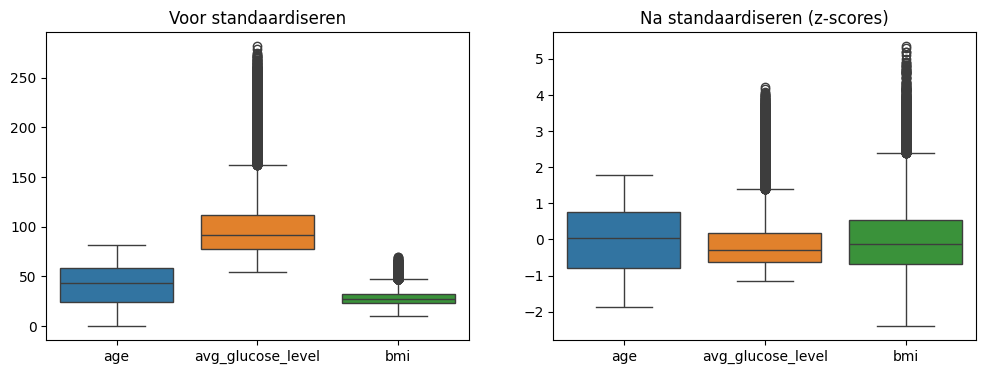

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=X_train[NUMERIC_COLS], ax=axes[0])
axes[0].set_title("Voor standaardiseren")
sns.boxplot(data=X_scaled[NUMERIC_COLS], ax=axes[1])
axes[1].set_title("Na standaardiseren (z-scores)")
plt.show()

**Resultaat**

Na het standaardiseren is het gemiddelde van elke kolom 0 en de standaardafwijking 1. Soms staat er `-0.0` in de output, maar dat is gewoon 0. Het komt door een heel klein afrondingsverschil van de computer.

**Voegt het hier waarde toe?** Ja. `age`, `avg_glucose_level` en `bmi` hebben allemaal een andere schaal (zie 2.3) en we gaan KNN, SVM en logistische regressie gebruiken. De 0/1-kolommen laten we zoals ze zijn, want die hebben al een kleine schaal die voor alle kolommen gelijk is.

**Belangrijk voor hoofdstuk 4:** `X_scaled` gebruiken we hier alleen om te laten zien wat standaardiseren doet. Bij het trainen met cross-validatie stoppen we de scaler in een `Pipeline`. Zo berekent die het gemiddelde en de standaardafwijking alleen op het trainingsdeel van elke fold. Als we dat niet doen, komt er informatie uit het validatiedeel in het model terecht (data leakage), waardoor de score beter lijkt dan hij echt is.

## 3. Evaluatie

### 3.1 Metrics

In [56]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Features en doelvariabele
X = train_clean.drop(columns="stroke")
y = train_clean["stroke"]

# Verdeelt de data in 80% training en 20% validatie
X_train_eval, X_val, y_train_eval, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standaardiseert alle numerieke kolommen, de rest blijft gelijk
preprocessor = ColumnTransformer(
    transformers=[
        ("scaler", StandardScaler(), NUMERIC_COLS)
    ],
    remainder="passthrough"
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])
\

model.fit(X_train_eval, y_train_eval)

# Voorspelt  de validatiedata
y_pred = model.predict(X_val)

# Berekent de metrics van de formule
print("Accuracy:", round(accuracy_score(y_val, y_pred), 4))
print("Precision:", round(precision_score(
    y_val, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_pred), 4))
print("F1-score:", round(f1_score(y_val, y_pred), 4))

print("\nClassification report:")
print(classification_report(y_val, y_pred, zero_division=0))


Accuracy: 0.9846
Precision: 0.0
Recall: 0.0
F1-score: 0.0

Classification report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      6604
           1       0.00      0.00      0.00       103

    accuracy                           0.98      6707
   macro avg       0.49      0.50      0.50      6707
weighted avg       0.97      0.98      0.98      6707






Bij classificatie voorspelt een machinelearningmodel tot welke klasse een patiënt behoort. In onze dataset betekent `stroke = 0` dat een patiënt geen herseninfarct heeft gehad en `stroke = 1` dat een patiënt wel een herseninfarct heeft gehad.

Om te bepalen hoe goed ons model presteert, gebruiken we verschillende evaluatiemetrics.

**Accuracy**

Accuracy geeft aan welk percentage van alle voorspellingen correct is. Hierbij wordt gekeken naar zowel de correct voorspelde patiënten zonder stroke als de correct voorspelde patiënten met stroke.

**Precision**

Precision geeft aan hoeveel patiënten daadwerkelijk een stroke hebben gehad van alle patiënten waarbij het model een stroke voorspelt.

**Recall**

Recall geeft aan hoeveel patiënten met een stroke correct worden herkend door het model.

**F1-score**

De F1-score is het harmonisch gemiddelde van precision en recall. Deze metric houdt rekening met zowel False Positives als False Negatives.

Voor onze evaluatie gebruiken we Logistic Regression als basismodel. Dit model is relatief eenvoudig en goed uitlegbaar.

We verdelen de dataset in 80% trainingsdata en 20% validatiedata. Hierbij gebruiken we `stratify=y`, zodat de verhouding tussen patiënten met en zonder stroke ongeveer gelijk blijft.

Om data leakage te voorkomen, wordt de standaardisatie uitsluitend op de trainingsdata getraind.



### 3.2 Confusion matrix

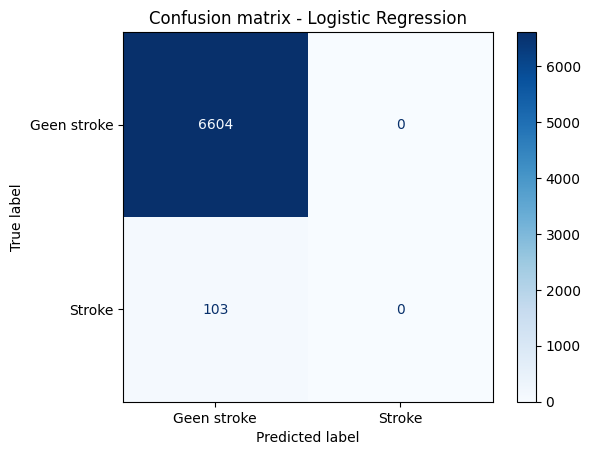

True Negatives: 6604
False Positives: 0
False Negatives: 103
True Positives: 0

Handmatig berekende metrics:
Accuracy: 0.9846
Precision: 0.0000
Recall: 0.0000
F1-score: 0.0000


In [57]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Berekent de confusion matrix
cm = confusion_matrix(y_val, y_pred, labels=[0, 1])


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Geen stroke", "Stroke"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix - Logistic Regression")
plt.show()

# Haalt de vier onderdelen van de confusion matrix op
tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

# Berekent de metrics met de formules
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if tp + fp > 0 else 0
recall = tp / (tp + fn) if tp + fn > 0 else 0

f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall > 0 else 0
)

print("\nHandmatig berekende metrics:")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")






Een confusion matrix laat zien hoeveel voorspellingen van een classificatiemodel correct en incorrect zijn.

De confusion matrix bestaat uit vier onderdelen:

- **True Positive (TP):** Het model voorspelt een stroke en de patiënt heeft daadwerkelijk een stroke gehad.
- **True Negative (TN):** Het model voorspelt geen stroke en de patiënt heeft daadwerkelijk geen stroke gehad.
- **False Positive (FP):** Het model voorspelt een stroke, maar de patiënt heeft geen stroke gehad.
- **False Negative (FN):** Het model voorspelt geen stroke, maar de patiënt heeft wel een stroke gehad.

Voor onze medische toepassing zijn False Negatives extra belangrijk. Dit zijn patiënten die een stroke hebben gehad, maar die niet door het model worden herkend.

Met de waarden uit de confusion matrix kunnen we verschillende evaluatiemetrics berekenen.

**Accuracy**

Accuracy is het aantal correcte voorspellingen gedeeld door het totale aantal voorspellingen.

$$
Accuracy = \frac{TP + TN}{TP + TN + FP + FN}
$$

**Precision**

Precision is het aantal True Positives gedeeld door alle positief voorspelde patiënten.

$$
Precision = \frac{TP}{TP + FP}
$$

**Recall**

Recall is het aantal True Positives gedeeld door alle patiënten die daadwerkelijk een stroke hebben gehad.

$$
Recall = \frac{TP}{TP + FN}
$$

**F1-score**

De F1-score combineert precision en recall tot één score.

$$
F1 = 2 \times \frac{Precision \times Recall}{Precision + Recall}
$$

Een hoge F1-score betekent dat het model een goede balans heeft tussen precision en recall.

Bij de evaluatie gebruiken we de confusion matrix om te onderzoeken welke fouten het model maakt en welke gevolgen deze fouten kunnen hebben.


### 3.3 Waarom F1-score?




Voor deze opdracht gebruiken we de F1-score als belangrijkste evaluatiemetric. Dit komt doordat onze dataset sterk imbalanced is.

Uit onze Exploratieve Data Analyse (EDA) blijkt dat slechts 1,54% van de patiënten een stroke heeft gehad. De overige 98,46% heeft geen stroke gehad.

Dit betekent dat de twee klassen niet gelijk verdeeld zijn.

Wanneer een model bij iedere patiënt voorspelt dat deze geen stroke heeft gehad, behaalt het al een accuracy van ongeveer 98,46%. Toch herkent dit model geen enkele patiënt die daadwerkelijk een stroke heeft gehad.

Hierdoor kan accuracy een misleidend beeld geven van de prestaties van het model.

De F1-score is in deze situatie een geschiktere evaluatiemetric, omdat deze rekening houdt met zowel precision als recall.

- **Precision:** Hoeveel van de voorspelde strokegevallen zijn daadwerkelijk strokegevallen?
- **Recall:** Hoeveel van de daadwerkelijke strokegevallen worden correct herkend?

Voor onze medische toepassing is recall extra belangrijk. Een False Negative betekent namelijk dat een patiënt met een stroke niet wordt herkend door het model.

Tegelijkertijd is precision belangrijk, omdat te veel False Positives kunnen leiden tot onnodige vervolgonderzoeken.

De F1-score combineert deze twee metrics en zorgt ervoor dat een model niet alleen goed scoort door de grootste klasse te voorspellen.

Daarom gebruiken we de F1-score om de verschillende machinelearningmodellen in deze Kaggle-competitie met elkaar te vergelijken.

Hoewel de F1-score geschikt is voor deze competitie, is het voor een medische toepassing ook belangrijk om afzonderlijk naar recall en precision te kijken.


## 4. Modellen

### 4.1 Imbalanced data



#### Uitleg

Onze dataset is niet gelijk verdeeld. Ongeveer 1,54% van de patiënten heeft een stroke gehad en 98,46% niet. Dit noemen we imbalanced data.

Dit kan een probleem zijn, omdat een model dan vooral leert om 'geen stroke' te voorspellen. Hierdoor kan het model een hoge accuracy halen, terwijl het bijna geen echte strokegevallen herkent.

Er zijn verschillende manieren om hiermee om te gaan.

**1. Class weights**

Met class weights geven we de kleinere groep meer gewicht tijdens het trainen. Hierdoor let het model meer op patiënten die wel een stroke hebben gehad.

Dit kunnen we doen met `class_weight="balanced"`.

**2. Oversampling**

Bij oversampling voegen we extra voorbeelden toe aan de kleinere groep.

Met RandomOverSampler worden bestaande voorbeelden opnieuw gebruikt. Met SMOTE worden nieuwe voorbeelden gemaakt op basis van bestaande gegevens.

**3. Undersampling**

Bij undersampling halen we een deel van de grootste groep weg. Zo worden de groepen meer gelijk verdeeld.

Het nadeel is dat we hierdoor ook informatie kunnen verliezen.

**4. Threshold tuning**

Normaal voorspelt een model bij een kans vanaf 0,5 dat iemand een stroke heeft gehad.

We kunnen deze grens verlagen, zodat het model meer strokegevallen herkent. Het nadeel is dat er dan ook vaker onterecht een stroke wordt voorspeld.

**Onze aanpak**

We gebruiken stratified cross-validation. Hiermee blijft de verhouding tussen patiënten met en zonder stroke ongeveer gelijk bij het testen.

Ook kijken we of class weights en andere methodes de F1-score verbeteren.

Als we oversampling of undersampling gebruiken, doen we dit alleen op de trainingsdata. Zo voorkomen we dat het model informatie gebruikt die het eigenlijk nog niet mag weten.

#### Resultaten


Aantal patiënten per klasse:
stroke
0    33014
1      517
Name: count, dtype: int64

Percentage per klasse:
stroke
0    98.46
1     1.54
Name: proportion, dtype: float64


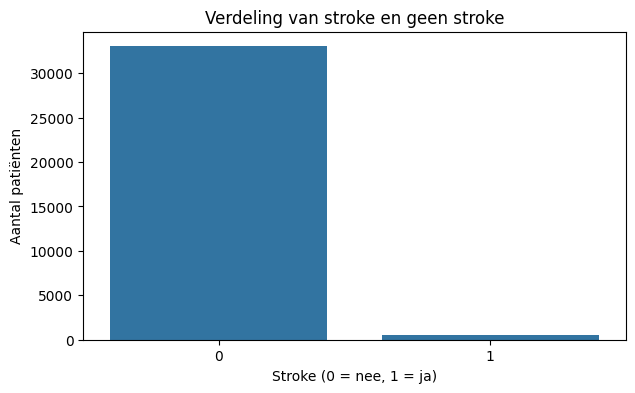

In [58]:

# Hier bekijken we de verdeling van wel en geen stroke
class_counts = train_clean[TARGET].value_counts()
class_percentages = (
    train_clean[TARGET].value_counts(normalize=True) * 100
)

print("Aantal patiënten per klasse:")
print(class_counts)

print("\nPercentage per klasse:")
print(class_percentages.round(2))

# Visualiseer de verdeling van stroke en geen stroke
plt.figure(figsize=(7, 4))
sns.countplot(data=train_clean, x=TARGET)
plt.title("Verdeling van stroke en geen stroke")
plt.xlabel("Stroke (0 = nee, 1 = ja)")
plt.ylabel("Aantal patiënten")
plt.show()



### 4.2 K-Nearest Neighbors

#### Uitleg

K-Nearest Neighbors (KNN) is een algoritme dat voorspellingen maakt door te kijken naar patiënten die op elkaar lijken.

KNN zoekt naar de K dichtstbijzijnde patiënten in de trainingsdata. Daarna kijkt het model welke uitkomst het vaakst voorkomt.

Als bijvoorbeeld 3 van de 5 dichtstbijzijnde patiënten een stroke hebben gehad, voorspelt KNN ook een stroke.

**Afstanden**

Om te bepalen welke patiënten het meest op elkaar lijken, berekent KNN de afstand tussen hun kenmerken.

Hiervoor kunnen we twee methodes gebruiken: Euclidean Distance en Manhattan Distance.

**Euclidean Distance**

Dit is de afstand in een rechte lijn tussen twee punten.

$$
d(x,y) = \sqrt{\sum_{i=1}^{n}(x_i-y_i)^2}
$$

**Manhattan Distance**

Hierbij worden de verschillen tussen de kenmerken bij elkaar opgeteld, zonder rekening te houden met mintekens.

$$
d(x,y) = \sum_{i=1}^{n}|x_i-y_i|
$$

**Rekenvoorbeeld**

Stel dat we twee patiënten hebben met de volgende waarden:

- Patiënt A: (1, 2)
- Patiënt B: (4, 6)

Bij Euclidean Distance krijgen we:

$$
d(A,B) = \sqrt{(4-1)^2+(6-2)^2} = 5
$$

Bij Manhattan Distance krijgen we:

$$
d(A,B) = |4-1|+|6-2| = 7
$$

Dit voorbeeld laat zien dat beide methodes een andere afstand kunnen berekenen.

**Standaardiseren**

Bij KNN is standaardiseren belangrijk, omdat het model met afstanden werkt.

In onze dataset heeft bijvoorbeeld `avg_glucose_level` veel grotere waarden dan een kolom met alleen 0 en 1.

Hierdoor zou glucose te veel invloed kunnen krijgen op de afstand. Daarom gebruiken we StandardScaler om de numerieke kolommen te standaardiseren.

**Regularisatie**

KNN gebruikt geen L1- of L2-regularisatie zoals sommige andere modellen.

We kunnen het model wel aanpassen door het aantal buren (K) te veranderen.

Bij een kleine K kijkt het model naar weinig patiënten. Hierdoor kan het te veel rekening houden met uitzonderingen in de data (overfitting).

Bij een grotere K kijkt het model naar meer patiënten. Dit geeft vaak stabielere voorspellingen, maar bij een te grote K kan underfitting ontstaan.

Met `weights="distance"` kunnen we patiënten die dichterbij liggen ook meer invloed geven op de voorspelling.

**Hyperparameter tuning**

We testen verschillende instellingen om te kijken welke het beste werken:

- `n_neighbors`: hoeveel buren KNN gebruikt.
- `weights`: of alle buren evenveel meetellen.
- `p`: welke afstandsmethode wordt gebruikt (1 = Manhattan, 2 = Euclidean).

Hiervoor gebruiken we GridSearchCV met stratified 5-fold cross-validation. We vergelijken de instellingen op basis van de F1-score.

#### Resultaten


In [59]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer


cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Standaardiseren binnen de pipeline om data leakage te voorkomen
knn_preprocessor = ColumnTransformer(
    transformers=[
        ("scaler", StandardScaler(), NUMERIC_COLS)
    ],
    remainder="passthrough"
)

knn_pipeline = Pipeline([
    ("preprocessor", knn_preprocessor),
    ("classifier", KNeighborsClassifier())
])

# Verschillende hyperparameters testen
knn_params = {
    "classifier__n_neighbors": [3, 5, 11, 21, 51],
    "classifier__weights": ["uniform", "distance"],
    "classifier__p": [1, 2]
}

knn_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_params,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

# Trainen op alleen het trainingsgedeelte
knn_search.fit(X_train_eval, y_train_eval)

print("Beste hyperparameters:")
print(knn_search.best_params_)

print(
    "Beste F1-score (cross-validatie):",
    round(knn_search.best_score_, 4)
)

# Evalueert op de aparte validatieset
knn_pred = knn_search.predict(X_val)

print("\nF1-score validatie:")
print(round(f1_score(y_val, knn_pred), 4))

print("\nClassification report:")
print(classification_report(y_val, knn_pred, zero_division=0))


Beste hyperparameters:
{'classifier__n_neighbors': 3, 'classifier__p': 2, 'classifier__weights': 'distance'}
Beste F1-score (cross-validatie): 0.0387

F1-score validatie:
0.0145

Classification report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      6604
           1       0.03      0.01      0.01       103

    accuracy                           0.98      6707
   macro avg       0.51      0.50      0.50      6707
weighted avg       0.97      0.98      0.97      6707




### 4.3 Logistic Regression

#### Uitleg

Logistic Regression is een model dat berekent hoe groot de kans is dat iets bij een bepaalde klasse hoort.

In ons geval voorspelt het model hoe groot de kans is dat een patiënt een stroke heeft gehad (`stroke = 1`).

Het model gebruikt hiervoor de kenmerken van een patiënt, zoals leeftijd, BMI en glucosewaarde.

Eerst berekent het model een waarde met deze formule:

$$
z = w_1x_1 + w_2x_2 + ... + w_nx_n + b
$$

Hierbij betekent:

- $x$: de kenmerken van de patiënt.
- $w$: hoe zwaar elk kenmerk meetelt.
- $b$: een extra waarde (bias).
- $z$: de uitkomst van de berekening.

Daarna gebruikt het model de sigmoidfunctie:

$$
\sigma(z) = \frac{1}{1+e^{-z}}
$$

Deze functie zet de uitkomst om naar een kans tussen 0 en 1.

Als deze kans boven de gekozen grens ligt, voorspelt het model een stroke.

**Loss-functie**

Om te kijken hoe goed het model voorspelt, gebruiken we de log loss.

$$
L = -\frac{1}{m}\sum_{i=1}^{m}
[y_i\log(p_i)+(1-y_i)\log(1-p_i)]
$$

Hierbij betekent:

- $m$: het aantal patiënten.
- $y_i$: de echte uitkomst (0 of 1).
- $p_i$: de kans die het model voorspelt.

De loss geeft aan hoe goed de voorspelde kansen kloppen. Hoe lager de loss, hoe beter.

**Gradient descent**

Gradient descent is een manier om het model te verbeteren.

Het model past hierbij de gewichten steeds een beetje aan om de loss lager te maken.

De formule hiervoor is:

$$
w_{nieuw} = w_{oud} - \alpha \frac{\partial L}{\partial w}
$$

Hierbij is $\alpha$ de learning rate. Die bepaalt hoe groot de aanpassing per stap is.

**Rekenvoorbeeld**

Stel dat we de volgende waarden hebben:

- $x = 1$
- $y = 1$
- $w = 0$
- $b = 0$
- Learning rate = 0,1

Eerst berekenen we de voorspelde kans:

$$
p = \sigma(0) = 0,5
$$

Daarna berekenen we hoeveel het gewicht moet veranderen:

$$
\frac{\partial L}{\partial w} = (p-y)x
$$

We vullen de waarden in:

$$
(0,5-1)\times1 = -0,5
$$

Nu berekenen we het nieuwe gewicht:

$$
w_{nieuw} = 0-0,1\times(-0,5)=0,05
$$

Het gewicht gaat dus van 0 naar 0,05.

Hierdoor wordt de voorspelde kans voor dit voorbeeld iets hoger. Dit is één stap van gradient descent.

**Regularisatie**

Regularisatie helpt om overfitting te voorkomen. Bij overfitting leert een model de trainingsdata te goed, waardoor het minder goed werkt op nieuwe gegevens.

Bij Logistic Regression zijn er verschillende soorten regularisatie.

**L1-regularisatie (Lasso)**

$$
L_{totaal} = L + \lambda\sum_{j=1}^{n}|w_j|
$$

Bij L1 kunnen sommige gewichten helemaal 0 worden. Hierdoor gebruikt het model bepaalde kenmerken uiteindelijk niet meer.

**L2-regularisatie (Ridge)**

$$
L_{totaal} = L + \lambda\sum_{j=1}^{n}w_j^2
$$

Bij L2 worden grote gewichten kleiner gemaakt. Meestal worden ze niet helemaal 0.

**Elastic Net**

Elastic Net is een combinatie van L1 en L2.

$$
L_{totaal} = L +
\lambda\left[
r\sum_{j=1}^{n}|w_j|+
(1-r)\sum_{j=1}^{n}w_j^2
\right]
$$

Hierbij bepaalt $r$ hoeveel invloed L1 en L2 hebben.

In Python gebruiken we de parameter `C` om de sterkte van regularisatie te bepalen.

- Kleine C: meer regularisatie.
- Grote C: minder regularisatie.

Te weinig regularisatie kan voor overfitting zorgen. Te veel regularisatie kan ervoor zorgen dat het model te simpel wordt (underfitting).

**Hyperparameter tuning**

We testen verschillende instellingen om te kijken welke het beste werken.

We vergelijken verschillende waarden voor `C`, de soorten regularisatie (`L1` en `L2`) en `class_weight`.

Met GridSearchCV en stratified 3-fold cross-validation zoeken we naar de instellingen met de beste F1-score.

#### Resultaten


In [60]:

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import f1_score, classification_report

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Numerieke kolommen standaardiseren
logistic_pipeline = Pipeline([
    ("preprocessor", ColumnTransformer(
        transformers=[
            ("scaler", StandardScaler(), NUMERIC_COLS)
        ],
        remainder="passthrough"
    )),
    ("classifier", LogisticRegression(
        solver="liblinear",
        max_iter=1000,
        random_state=42
    ))
])

# Verschillende instellingen testen
logistic_params = {
    "classifier__penalty": ["l1", "l2"],
    "classifier__C": [0.1, 1, 10],
    "classifier__class_weight": [None, "balanced"]
}

# Beste instellingen zoeken
logistic_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_params,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=2
)

# Hier trainen we het model 
logistic_search.fit(X_train_eval, y_train_eval)

print("\nBeste parameters:")
print(logistic_search.best_params_)

print("\nBeste F1-score cross-validation:")
print(round(logistic_search.best_score_, 4))

# Voorspellingen maken
logistic_pred = logistic_search.predict(X_val)

print("\nF1-score validatie:")
print(round(f1_score(y_val, logistic_pred), 4))

print("\nClassification report:")
print(classification_report(
    y_val,
    logistic_pred,
    zero_division=0
))



Fitting 3 folds for each of 12 candidates, totalling 36 fits

Beste parameters:
{'classifier__C': 0.1, 'classifier__class_weight': 'balanced', 'classifier__penalty': 'l1'}

Beste F1-score cross-validation:
0.0946

F1-score validatie:
0.0829

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.75      0.85      6604
           1       0.04      0.74      0.08       103

    accuracy                           0.75      6707
   macro avg       0.52      0.74      0.47      6707
weighted avg       0.98      0.75      0.84      6707



c:\Users\Aroetin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Aroetin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(



### 4.4 Support Vector Machine

#### Uitleg

Support Vector Machine (SVM) is een model dat gebruikt wordt om gegevens in verschillende klassen in te delen.

Het model probeert een grens te vinden die de twee groepen zo goed mogelijk uit elkaar houdt. In onze dataset gaat het om patiënten die wel of geen stroke hebben gehad.

Deze grens noemen we de decision boundary.

Bij een lineaire SVM gebruiken we de volgende formule:

$$
f(x) = w^Tx+b
$$

Hierbij betekent:

- $w$: de gewichten van de kenmerken.
- $x$: de kenmerken van een patiënt.
- $b$: een extra waarde (bias).

SVM probeert de grens zo te plaatsen dat er zoveel mogelijk ruimte zit tussen de grens en de dichtstbijzijnde punten.

Deze ruimte noemen we de margin. De punten die het dichtst bij de grens liggen, heten support vectors.

**Rekenvoorbeeld**

Stel dat we twee patiënten hebben met gestandaardiseerde waarden:

- Patiënt A: leeftijd = -1, glucose = -1, klasse = 0.
- Patiënt B: leeftijd = 1, glucose = 1, klasse = 1.

We gebruiken voor dit voorbeeld de formule:

$$
f(x) = x_1+x_2
$$

Voor patiënt A:

$$
f(A) = -1+(-1)=-2
$$

Voor patiënt B:

$$
f(B) = 1+1=2
$$

Patiënt A krijgt een negatieve uitkomst en wordt daarom ingedeeld in klasse 0.

Patiënt B krijgt een positieve uitkomst en wordt ingedeeld in klasse 1.

Dit is een simpel voorbeeld. Ons echte model gebruikt meer kenmerken om een voorspelling te maken.

**Kernels**

Soms kunnen groepen niet goed gescheiden worden met een rechte lijn.

Daarom kan SVM ook kernels gebruiken. Hiermee kan het model ingewikkeldere grenzen maken.

Er zijn verschillende kernels:

- **Linear:** gebruikt een rechte grens.
- **Polynomial:** kan een gebogen grens maken.
- **RBF:** kan ingewikkeldere patronen herkennen.

Met de kernel trick kan SVM ingewikkeldere verbanden berekenen zonder alle gegevens echt om te zetten naar extra dimensies.

De formule van de RBF-kernel is:

$$
K(x,z)=e^{-\gamma||x-z||^2}
$$

Hierbij bepaalt gamma ($\gamma$) hoeveel invloed de afstand tussen twee punten heeft.

**Loss-functie**

SVM gebruikt onder andere hinge loss om fouten te berekenen.

$$
L_i = \max(0,1-y_if(x_i))
$$

Bij deze formule is $y_i$ gelijk aan -1 of 1.

Als een voorspelling goed is en ver genoeg van de grens ligt, is de hinge loss 0.

De totale berekening kan zo worden weergegeven:

$$
\min_{w,b}\frac{1}{2}||w||^2+
C\sum_{i=1}^{m}\max(0,1-y_if(x_i))
$$

Het eerste deel zorgt ervoor dat de gewichten niet te groot worden.

Het tweede deel kijkt naar fouten en punten die te dicht bij de grens liggen.

**Regularisatie**

Bij SVM gebruiken we de parameter `C` om te bepalen hoe streng het model omgaat met fouten.

- **Kleine C:** het model staat meer fouten toe en probeert een grotere margin te houden.
- **Grote C:** het model probeert de trainingsdata zo goed mogelijk in te delen.

Een te grote C kan zorgen voor overfitting. Een te kleine C kan zorgen voor underfitting.

Bij de RBF-kernel gebruiken we ook `gamma`.

- **Kleine gamma:** punten hebben invloed op een groter gebied en de grens wordt meestal eenvoudiger.
- **Grote gamma:** punten hebben vooral invloed op hun directe omgeving en de grens kan ingewikkelder worden.

**Standaardiseren**

Net als bij KNN is standaardiseren belangrijk voor SVM.

Sommige kenmerken hebben namelijk veel grotere waarden dan andere. Zonder standaardisatie kunnen deze kenmerken te veel invloed krijgen.

Daarom gebruiken we StandardScaler voor de numerieke kolommen. Dit doen we binnen een pipeline, zodat er geen data leakage ontstaat.

**Hyperparameter tuning**

We testen verschillende instellingen om te kijken welke het beste werken.

Bij onze lineaire SVM testen we:

- `C`: hoe streng het model omgaat met fouten.
- `class_weight`: of we extra gewicht geven aan de kleinere klasse.

We gebruiken GridSearchCV met stratified 3-fold cross-validation en vergelijken de modellen op basis van de F1-score.

#### Resultaten


In [61]:

from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

# Lineaire SVM met standaardisatie
svm_pipeline = Pipeline([
    ("preprocessor", ColumnTransformer(
        transformers=[
            ("scaler", StandardScaler(), NUMERIC_COLS)
        ],
        remainder="passthrough"
    )),
    ("classifier", LinearSVC(
        dual=False,
        max_iter=5000,
        random_state=42
    ))
])

# Hyperparameters voor lineaire SVM
svm_params = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__class_weight": [
        None,
        "balanced",
        {0: 1, 1: 20}
    ]
}

svm_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_params,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

# Trainen en optimaliseren van het model
svm_search.fit(X_train_eval, y_train_eval)

print("Beste hyperparameters:")
print(svm_search.best_params_)

print(
    "Beste F1-score (cross-validatie):",
    round(svm_search.best_score_, 4)
)

# Voorspellen van de validatiedata
svm_pred = svm_search.predict(X_val)

print("\nF1-score validatie:")
print(round(f1_score(y_val, svm_pred), 4))

print("\nClassification report:")
print(classification_report(
    y_val, svm_pred, zero_division=0
))


Beste hyperparameters:
{'classifier__C': 0.1, 'classifier__class_weight': {0: 1, 1: 20}}
Beste F1-score (cross-validatie): 0.1422

F1-score validatie:
0.1339

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.91      0.95      6604
           1       0.08      0.50      0.13       103

    accuracy                           0.90      6707
   macro avg       0.53      0.70      0.54      6707
weighted avg       0.98      0.90      0.94      6707



### 4.5 Decision Tree

#### Uitleg

**Werking.** 

Een decision tree stelt achter elkaar ja/nee-vragen over één kolom, bijvoorbeeld "is `age` ≤ 51,5?". Daardoor worden de patiënten steeds opgedeeld in kleinere groepen. Aan het eind van een tak (een blad) voorspelt de boom de klasse die in die groep het zwaarst weegt. Bij elke stap kiest de boom de vraag waarbij de groepen daarna het minst gemengd zijn, dus zoveel mogelijk alleen stroke of alleen geen stroke.

**Splitsingscriteria.** 

Om te meten hoe gemengd een groep is, zijn er twee maten. Hierbij is $p_i$ het aandeel van klasse $i$ in de groep.

* Gini: $G = 1 - \sum p_i^2$
* Entropy: $H = -\sum p_i \log_2 p_i$

Bij beide is de waarde 0 als de groep helemaal zuiver is, en hoe hoger de waarde, hoe gemengder de groep. De boom kiest de splitsing waarbij de waarde het meest daalt.

Een voorbeeld met onze eigen data: in de bovenste knoop zitten 33.014 patiënten zonder stroke en 10.340 met stroke (de 517 stroke-patiënten tellen door `class_weight` 20 keer mee). Dan is $p_0 = 33.014 / 43.354 \approx 0{,}7615$ en $p_1 \approx 0{,}2385$. Daarmee krijgen we $H = -(0{,}7615 \log_2 0{,}7615 + 0{,}2385 \log_2 0{,}2385) \approx 0{,}793$ en $G = 1 - (0{,}7615^2 + 0{,}2385^2) \approx 0{,}363$.

**Pruning.** 

Pruning ("snoeien") zorgt ervoor dat de boom niet te groot wordt, zodat hij niet gaat leren van toevalligheden in de trainingsdata.

* Pre-pruning (hebben wij gedaan): we beperken de boom al tijdens het groeien met `max_depth` (maximale diepte) en `min_samples_leaf` (minimaal aantal patiënten per blad).
* Post-pruning (niet gedaan): de boom groeit eerst volledig uit en daarna worden de takken weggehaald die weinig toevoegen. Dit kan in scikit-learn met `ccp_alpha`.

**Pruning en over-/underfitting.** 

Zonder pruning blijft de boom splitsen tot elk blad zuiver is. Dan onthoudt hij als het ware de trainingsdata (overfitting) en voorspelt hij nieuwe patiënten slecht. Als je te veel snoeit, wordt de boom juist te simpel en mist hij patronen (underfitting). Met cross-validatie zoeken we de diepte die hier tussenin zit.

**Imbalanced data.** 

Omdat maar 1,54% van de patiënten een stroke heeft, gebruiken we `class_weight`. Een fout bij een stroke-patiënt telt daardoor zwaarder dan een fout bij iemand zonder stroke. Zonder deze weging zou de boom bijna altijd "geen stroke" voorspellen, want dan heeft hij al vaak gelijk.

#### Resultaten

In [62]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier

# 5 folds; stratify zorgt dat iedere fold ongeveer 1,54% stroke heeft
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

tree = DecisionTreeClassifier(random_state=42)

param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [3, 4, 5, 6, 8, 10],
    "min_samples_leaf": [1, 20, 50, 100],
    # Hoeveel zwaarder een gemiste stroke telt dan een vals alarm
    "class_weight": [{0: 1, 1: 5}, {0: 1, 1: 10}, {0: 1, 1: 20},
                     "balanced"],
}

tree_search = GridSearchCV(tree, param_grid, scoring="f1", cv=cv,
                           n_jobs=-1)
tree_search.fit(X_train, y_train)

print("Beste hyperparameters:", tree_search.best_params_)
print(f"Beste F1 (cross-validatie): {tree_search.best_score_:.4f}")

Beste hyperparameters: {'class_weight': {0: 1, 1: 20}, 'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 50}
Beste F1 (cross-validatie): 0.1337


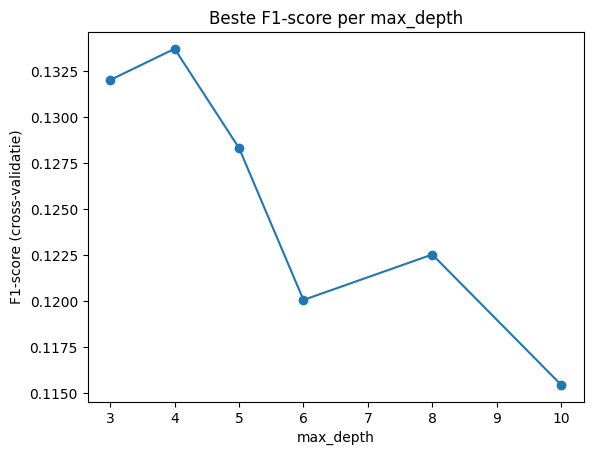

In [63]:
results = pd.DataFrame(tree_search.cv_results_)
f1_per_depth = results.groupby("param_max_depth")["mean_test_score"].max()

f1_per_depth.plot(marker="o")
plt.title("Beste F1-score per max_depth")
plt.xlabel("max_depth")
plt.ylabel("F1-score (cross-validatie)")
plt.show()

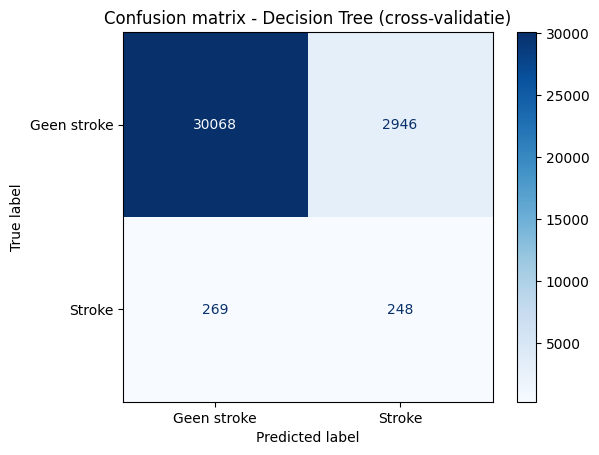

In [64]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_predict

best_tree = tree_search.best_estimator_

# Voorspelling per fold, zodat iedere patiënt één keer validatie is
y_pred_cv = cross_val_predict(best_tree, X_train, y_train, cv=cv)
ConfusionMatrixDisplay.from_predictions(
    y_train, y_pred_cv, display_labels=["Geen stroke", "Stroke"],
    cmap="Blues", values_format="d")
plt.title("Confusion matrix - Decision Tree (cross-validatie)")
plt.show()

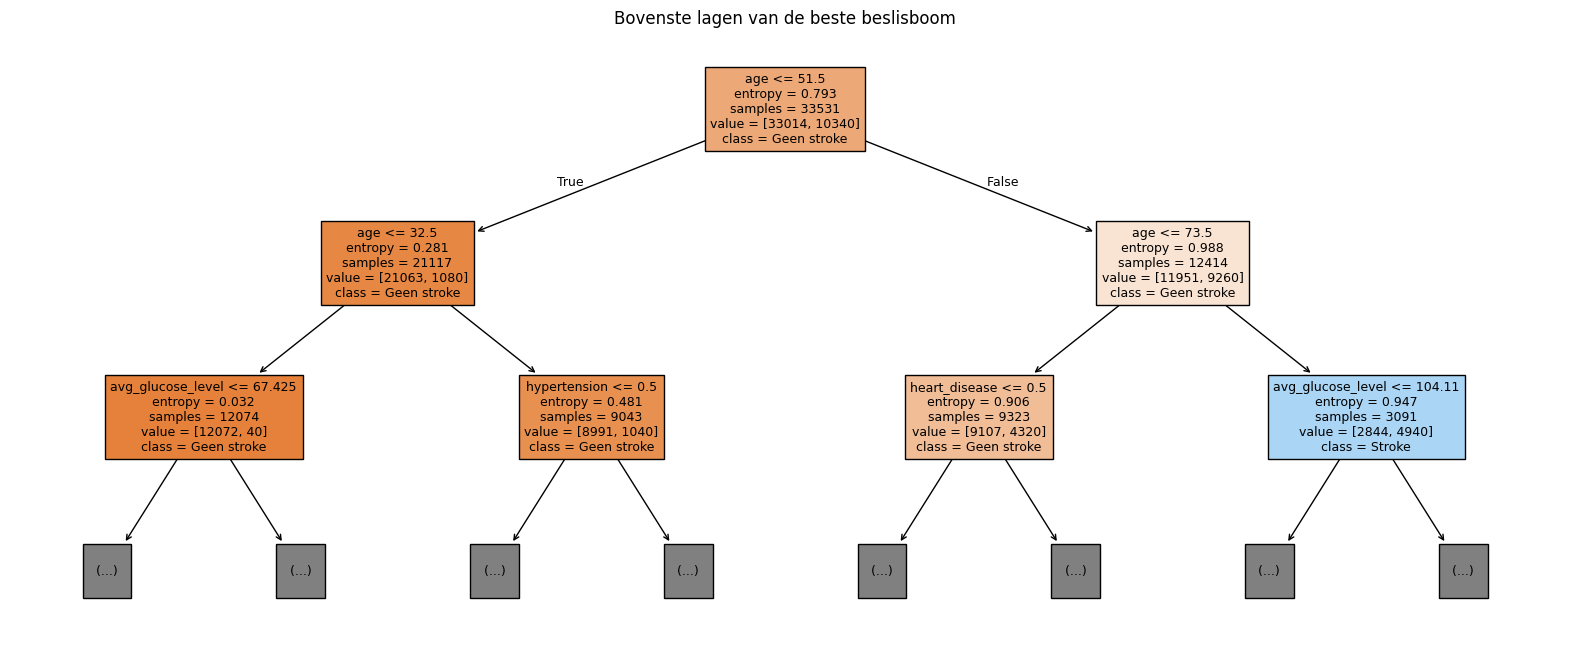

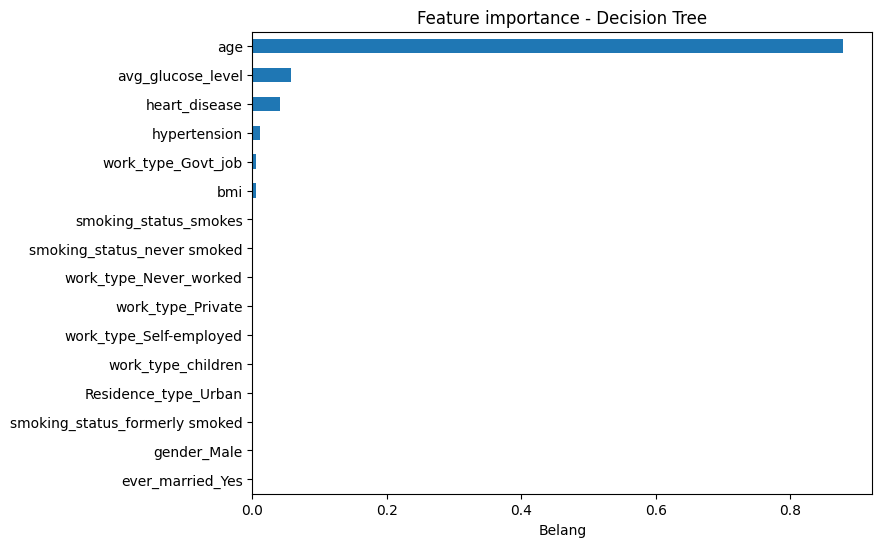

In [65]:
from sklearn.tree import plot_tree

best_tree.fit(X_train, y_train)

plt.figure(figsize=(20, 8))
plot_tree(best_tree, feature_names=X_train.columns, max_depth=2,
          class_names=["Geen stroke", "Stroke"], filled=True, fontsize=9)
plt.title("Bovenste lagen van de beste beslisboom")
plt.show()

importances = pd.Series(best_tree.feature_importances_,
                        index=X_train.columns).sort_values()
importances.plot(kind="barh", figsize=(8, 6))
plt.title("Feature importance - Decision Tree")
plt.xlabel("Belang")
plt.show()

**Beste hyperparameters.** 

Uit de grid search komt als beste combinatie `class_weight={0: 1, 1: 20}`, `criterion="entropy"`, `max_depth=4` en `min_samples_leaf=50`. Hiermee is de F1-score met cross-validatie 0,134. Door de weging telt een stroke-patiënt 20 keer zo zwaar mee. Daarom is `value` in de boomplot ook gewogen: 517 stroke-patiënten × 20 = 10.340.

**Diepte en overfitting.** 

De F1-score is het hoogst bij diepte 4 en wordt lager bij diepere bomen (0,115 bij diepte 10). Een diepere boom past zich te veel aan de trainingsdata aan, dat is overfitting. Hieraan zie je dus waarom pruning nodig is.

**Confusion matrix.** 

De boom vindt 248 van de 517 stroke-patiënten (recall ongeveer 48%), maar geeft daarbij ook 2.946 valse alarmen (precision ongeveer 8%). Dus bijna de helft van de strokes wordt gevonden, maar er worden ook veel patiënten onterecht als risico gezien. De F1-score van 0,134 is laag, en dat past bij hoe lastig het is om een stroke te voorspellen met deze data.

**Interpretatie.** 

De eerste vraag in de boom is "is `age` ≤ 51,5?". Bijvoorbeeld patiënten ouder dan 73,5 jaar met een glucosewaarde boven 104 worden voorspeld als stroke. Volgens de feature importance is leeftijd het belangrijkst (88%), daarna glucose (6%) en hartziekte (4%). Dit komt overeen met onze EDA (2.6). Een groot voordeel van een decision tree is dat je zo'n beslisregel makkelijk aan een arts kunt uitleggen.

### 4.6 Random Forest

#### Uitleg

**Ensemble.** 

Een Random Forest is een ensemble: in plaats van één beslisboom trainen we er heel veel. Iedere boom voorspelt "stroke" of "geen stroke", en de meerderheid van de stemmen bepaalt de uiteindelijke voorspelling.

**Bagging (bootstrap aggregation).** 

Iedere boom krijgt een eigen bootstrap-steekproef: een willekeurige trekking van evenveel rijen uit de trainingsdata, *met terugleggen*. Sommige patiënten komen daardoor meerdere keren voor in de steekproef van een boom en andere helemaal niet. Daarna worden de voorspellingen van alle bomen samengevoegd (aggregation).

**Extra willekeur.** 

Bij iedere splitsing kijkt een boom maar naar een willekeurig deel van de kolommen. Daardoor splitsen niet alle bomen steeds op `age`, en gaan ze meer van elkaar verschillen.

**Waarom beter dan één boom?** 

Eén boom is gevoelig voor toeval in de data (overfitting). Doordat veel verschillende bomen samen stemmen, vallen die toevallige fouten tegen elkaar weg.

**Trainingstijd: parallel.** 

De bomen zijn onafhankelijk van elkaar en kunnen daarom tegelijk (*parallel*) worden getraind. Met `n_jobs=-1` gebruiken we alle processorkernen. Daardoor is Random Forest relatief snel. Bij boosting (4.7 en 4.8) moeten de bomen juist na elkaar (*sequential*) worden getraind, omdat iedere boom leert van de fouten van de vorige.

**Hyperparameters.** 

`n_estimators` (aantal bomen), `max_depth` en `min_samples_leaf` (pruning per boom, zoals in 4.5) en `class_weight` (techniek voor imbalanced data).

#### Resultaten

In [66]:
from sklearn.ensemble import RandomForestClassifier

# n_jobs=-1: de bomen worden tegelijk (parallel) getraind op alle cores
forest = RandomForestClassifier(random_state=42, n_jobs=-1)

param_grid = {
    "n_estimators": [100, 300],
    "max_depth": [4, 6, 8, 10],
    "min_samples_leaf": [20, 50],
    "class_weight": [{0: 1, 1: 10}, {0: 1, 1: 20}, "balanced"],
}

forest_search = GridSearchCV(forest, param_grid, scoring="f1", cv=cv)
forest_search.fit(X_train, y_train)

print("Beste hyperparameters:", forest_search.best_params_)
print(f"Beste F1 (cross-validatie): {forest_search.best_score_:.4f}")

Beste hyperparameters: {'class_weight': {0: 1, 1: 20}, 'max_depth': 10, 'min_samples_leaf': 50, 'n_estimators': 300}
Beste F1 (cross-validatie): 0.1421


In [67]:
forest_results = pd.DataFrame(forest_search.cv_results_)

# Gemiddelde trainingstijd per fold en beste F1, per aantal bomen
forest_results.groupby("param_n_estimators").agg(
    trainingstijd_sec=("mean_fit_time", "mean"),
    beste_f1=("mean_test_score", "max"),
).round(3)

,trainingstijd_sec,beste_f1
param_n_estimators,,
100,0.182,0.142
300,0.499,0.142


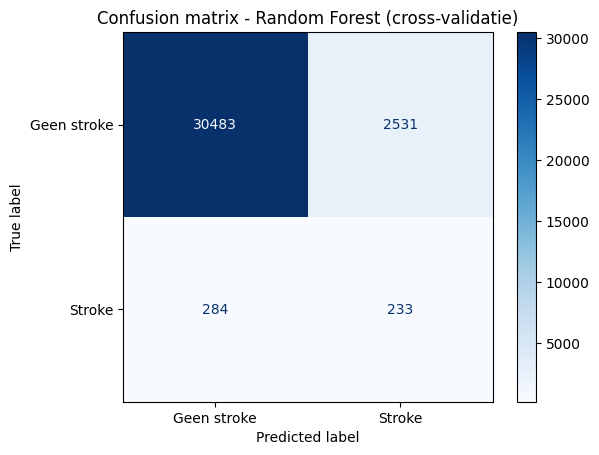

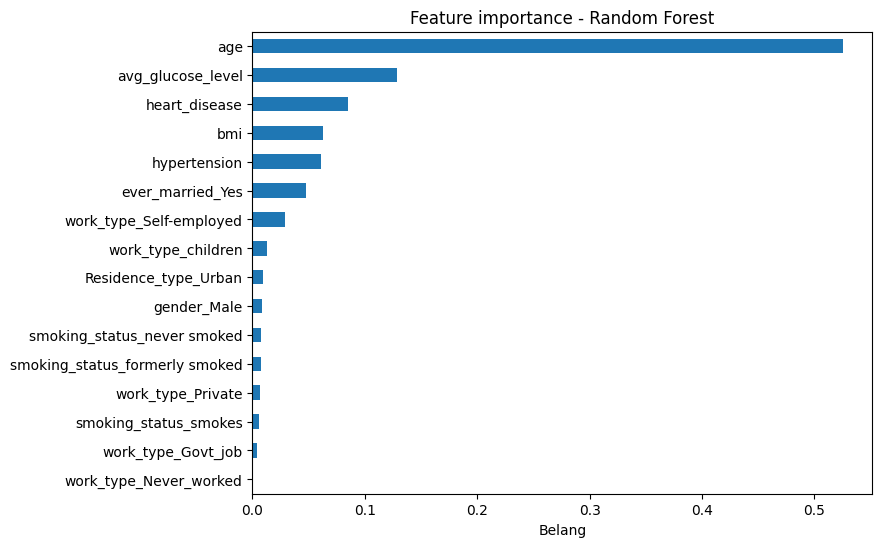

In [68]:
best_forest = forest_search.best_estimator_

y_pred_cv = cross_val_predict(best_forest, X_train, y_train, cv=cv)
ConfusionMatrixDisplay.from_predictions(
    y_train, y_pred_cv, display_labels=["Geen stroke", "Stroke"],
    cmap="Blues", values_format="d")
plt.title("Confusion matrix - Random Forest (cross-validatie)")
plt.show()

best_forest.fit(X_train, y_train)
forest_importances = pd.Series(best_forest.feature_importances_,
                               index=X_train.columns).sort_values()
forest_importances.plot(kind="barh", figsize=(8, 6))
plt.title("Feature importance - Random Forest")
plt.xlabel("Belang")
plt.show()

**Beste hyperparameters.** 

`class_weight={0: 1, 1: 20}`, `max_depth=10`, `min_samples_leaf=50` en `n_estimators=100`. Hiermee is de F1-score met cross-validatie **0,142**, iets hoger dan die van de enkele beslisboom (0,134).

**Aantal bomen en trainingstijd.** 

300 bomen scoren niet beter dan 100 bomen (allebei 0,142), maar de training duurt bijna drie keer zo lang (0,37 tegenover 0,13 seconde per fold). Meer bomen helpt dus maar tot een bepaald punt.

**Diepte.** 

Een Random Forest kan diepere bomen aan (beste bij diepte 10) dan één losse beslisboom (beste bij diepte 4). Doordat veel bomen samen stemmen, wordt het overfitten van de afzonderlijke bomen gedempt.

**Confusion matrix.** 

Het model vindt 231 van de 517 stroke-patiënten (recall ongeveer 45%) en geeft 2.503 valse alarmen. Dat zijn er minder dan bij de enkele beslisboom (2.946), waardoor de precision iets beter is.

**Feature importance.** 

Leeftijd is nog steeds het belangrijkst (50%), maar het belang is beter verdeeld dan bij één boom (88%). Ook glucose (13%), hartziekte (9%), hoge bloeddruk (7%) en bmi (6%) dragen nu bij.

## 4.7 Gradient Boosting

### Uitleg

**Werking.** 

Gradient Boosting is net als Random Forest een ensemble van beslisbomen. Het verschil zit in hoe de bomen samenwerken. Bij Random Forest worden alle bomen los van elkaar getraind en stemmen ze aan het eind. Bij boosting worden de bomen na elkaar getraind, en iedere nieuwe boom probeert de fouten van de vorige bomen te verbeteren.

De bomen zijn bewust klein, vaak maar 2 of 3 lagen diep. Eén zo'n boom is een zwak model. Maar als je er honderd achter elkaar zet die steeds een beetje verbeteren, krijg je samen toch een sterk model.

**Formule.** 

Het model begint met een simpele voorspelling $F_0$ en daarna komt er steeds een boom $h$ bij:

$$F_m(x) = F_{m-1}(x) + \eta \cdot h_m(x)$$

Hierbij is $\eta$ de learning rate. Die bepaalt hoe groot de stap is die iedere boom mag zetten. Iedere nieuwe boom wordt getraind op de fouten die het model tot nu toe maakt (het verschil tussen de echte uitkomst en de voorspelde kans). Dit lijkt op gradient descent uit 4.3, alleen pas je nu geen gewichten aan maar voeg je steeds een boom toe.

**Rekenvoorbeeld.** 

Stel een patiënt heeft een stroke ($y = 1$) en het model voorspelt nu een kans van 0,2. De fout is dan $1 - 0{,}2 = 0{,}8$. De volgende boom leert dat dit soort patiënten een hogere kans moet krijgen en geeft bijvoorbeeld een correctie van 0,5. Met een learning rate van 0,1 gaat de voorspelling maar $0{,}1 \times 0{,}5 = 0{,}05$ omhoog. Het model past zich dus in kleine stapjes aan.

**Regularisatie.** 

Boosting kan makkelijk overfitten, omdat iedere boom zich steeds meer richt op de lastige patiënten. Daarom kijken we naar drie hyperparameters:
- `learning_rate`: hoe groot iedere stap is. Kleiner is voorzichtiger.
- `n_estimators`: het aantal bomen. Te veel bomen gaat leren van ruis.
- `max_depth`: hoe diep iedere boom mag worden (pre-pruning, zoals in 4.5).

**Trainingstijd: sequentieel.** 

Iedere boom heeft de fouten van de vorige boom nodig. De bomen kunnen dus niet tegelijk worden getraind, zoals bij Random Forest wel kan. Daardoor is boosting trager.

**Imbalanced data.** 

`GradientBoostingClassifier` heeft geen `class_weight`. Daarom gebruiken we hier de vierde techniek uit 4.1: threshold tuning. We kiezen eerst de beste hyperparameters op ROC AUC. Die metric kijkt of patiënten met een stroke een hogere kans krijgen dan patiënten zonder stroke, los van de threshold. Daarna proberen we verschillende thresholds uit en kijken we welke de hoogste F1 geeft.

### Resultaten

In [69]:
from sklearn.ensemble import GradientBoostingClassifier

boosting = GradientBoostingClassifier(random_state=42)

param_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [2, 3],
}

# Bij threshold 0,5 is de F1 overal 0, daarom kiezen we op roc_auc
boosting_search = GridSearchCV(boosting, param_grid, scoring="roc_auc", cv=cv,
                               n_jobs=-1)
boosting_search.fit(X_train, y_train)

print("Beste hyperparameters:", boosting_search.best_params_)
print(f"Beste ROC AUC (cross-validatie): {boosting_search.best_score_:.4f}")

Beste hyperparameters: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100}
Beste ROC AUC (cross-validatie): 0.8549


In [70]:
best_boosting = boosting_search.best_estimator_

# Kans op stroke per patiënt, iedere patiënt één keer in de validatie-fold
kansen_boosting = cross_val_predict(best_boosting, X_train, y_train, cv=cv,
                                    method="predict_proba")[:, 1]

# Verschillende thresholds proberen
for threshold in [0.5, 0.2, 0.15, 0.1, 0.08, 0.06, 0.04]:
    voorspelling = (kansen_boosting >= threshold).astype(int)
    print(f"threshold {threshold}: F1 = {f1_score(y_train, voorspelling):.4f}, "
          f"aantal voorspeld als stroke = {voorspelling.sum()}")

threshold 0.5: F1 = 0.0000, aantal voorspeld als stroke = 0
threshold 0.2: F1 = 0.0147, aantal voorspeld als stroke = 29
threshold 0.15: F1 = 0.0261, aantal voorspeld als stroke = 95
threshold 0.1: F1 = 0.0944, aantal voorspeld als stroke = 648
threshold 0.08: F1 = 0.1367, aantal voorspeld als stroke = 1239
threshold 0.06: F1 = 0.1421, aantal voorspeld als stroke = 2481
threshold 0.04: F1 = 0.1332, aantal voorspeld als stroke = 3792


Bij de standaard threshold van 0,5 voorspelt het model bij niemand een stroke, dus de F1 is 0. Dat vinden we eigenlijk logisch: maar 1,54% van de patiënten heeft een stroke, dus het model komt bijna nooit boven een kans van 50% uit. Als we de threshold verlagen, gaat de F1 omhoog tot 0,142 bij een threshold van 0,06. Bij 0,04 daalt de F1 weer, omdat het model dan te veel valse alarmen geeft. Daarom kiezen we 0,06.

param_n_estimators
100    2.054
200    3.873
Name: mean_fit_time, dtype: float64


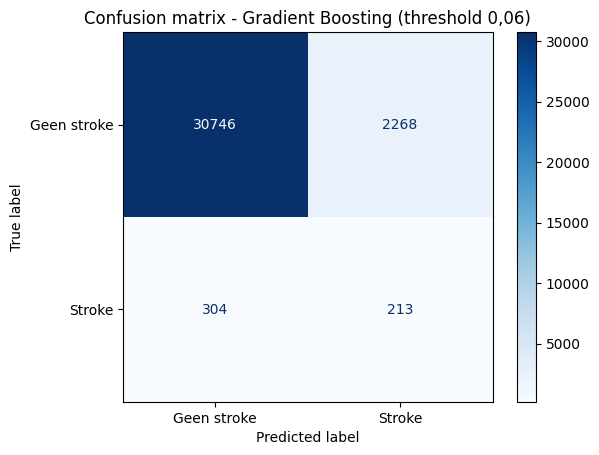

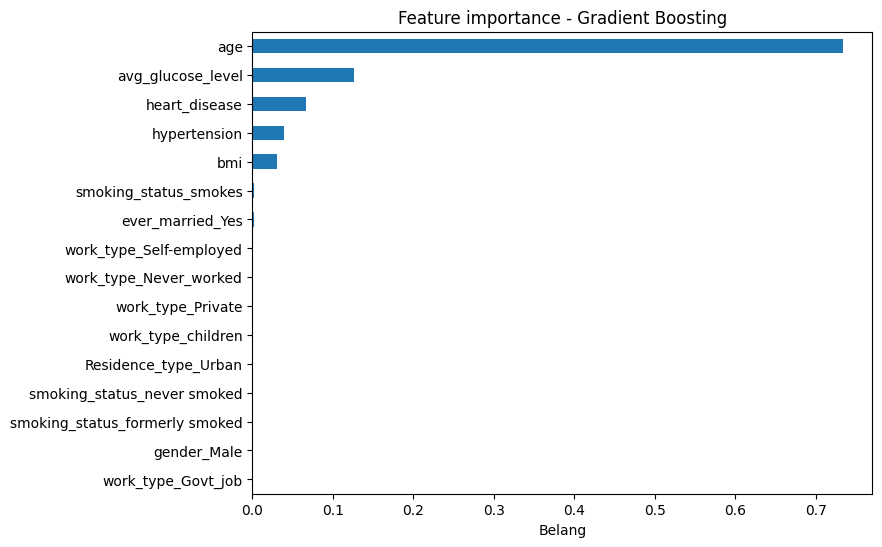

In [71]:
THRESHOLD_BOOSTING = 0.06

boosting_results = pd.DataFrame(boosting_search.cv_results_)
# Gemiddelde trainingstijd per fold, per aantal bomen
print(boosting_results.groupby("param_n_estimators")["mean_fit_time"]
      .mean().round(3))

ConfusionMatrixDisplay.from_predictions(
    y_train, (kansen_boosting >= THRESHOLD_BOOSTING).astype(int),
    display_labels=["Geen stroke", "Stroke"], cmap="Blues", values_format="d")
plt.title("Confusion matrix - Gradient Boosting (threshold 0,06)")
plt.show()

best_boosting.fit(X_train, y_train)
boosting_importances = pd.Series(best_boosting.feature_importances_,
                                 index=X_train.columns).sort_values()
boosting_importances.plot(kind="barh", figsize=(8, 6))
plt.title("Feature importance - Gradient Boosting")
plt.xlabel("Belang")
plt.show()

**Beste hyperparameters.** 

`learning_rate=0.05`, `max_depth=2` en `n_estimators=100`. Dit is de meest voorzichtige combinatie uit ons grid. Wat ons opviel is dat meer bomen of diepere bomen het model hier niet beter maken. Er zit blijkbaar niet zo veel informatie in de data die een ingewikkelder model nog kan vinden.

**Trainingstijd.** 

Met 200 bomen duurt het trainen bijna twee keer zo lang als met 100 bomen (3,9 tegenover 2,1 seconde per fold). Dat komt doordat de bomen na elkaar worden getraind. Random Forest deed 300 bomen in ongeveer 1 seconde, omdat die bomen tegelijk worden getraind.

**Confusion matrix.** 

Bij een threshold van 0,06 vindt het model ongeveer 213 van de 517 stroke-patiënten. Daar staan wel ongeveer 2.270 valse alarmen tegenover. Dat is vergelijkbaar met Random Forest (231 gevonden en 2.503 valse alarmen).

**Feature importance.** 

Leeftijd is weer het belangrijkst (73%), daarna glucose (13%) en hartziekte (7%). Dit sluit aan bij onze EDA (2.6) en bij de beslisboom en Random Forest.

**Kanttekening.** 

We kiezen de threshold op dezelfde voorspellingen waarop we de F1 berekenen. Eerlijk is eerlijk: daardoor is de score van 0,142 waarschijnlijk iets te positief.

## 4.8 XGBoost

### Uitleg

**Werking.** XGBoost (eXtreme Gradient Boosting) is een verbeterde en snellere versie van Gradient Boosting (Chen & Guestrin, 2016). Het idee is hetzelfde: de bomen worden na elkaar getraind en iedere boom verbetert de fouten van de vorige. Toch zijn er een paar verschillen.

**1. Regularisatie zit in de loss-functie.** Bij gewone Gradient Boosting regel je overfitting alleen met instellingen als `max_depth` en `learning_rate`. XGBoost telt er nog een strafterm bij op:

$$\text{Loss}_{\text{totaal}} = \text{Loss} + \lambda \sum_{j} w_j^2$$

Hierbij is $w_j$ de waarde die een blad van de boom voorspelt. Dit is hetzelfde idee als L2-regularisatie bij Logistic Regression (4.3). Een hoge $\lambda$ (`reg_lambda`) zorgt ervoor dat één boom de voorspelling niet te veel kan veranderen. Zo wordt het model voorzichtiger.

**Rekenvoorbeeld.** Stel dat een blad zonder regularisatie de voorspelling met 1,8 zou willen verhogen. In XGBoost wordt die waarde ongeveer gedeeld door een getal dat groter wordt met $\lambda$. Met $\lambda = 1$ blijft er dan bijvoorbeeld 1,6 over, maar met $\lambda = 10$ nog maar ongeveer 0,2. Een blad met weinig patiënten kan dus niet zomaar een grote sprong maken.

**2. Snelheid.** De bomen worden nog steeds na elkaar getraind, maar binnen één boom zoekt XGBoost de beste splitsingen tegelijk op meerdere processorkernen (`n_jobs`). Daardoor is het sneller dan de gewone `GradientBoostingClassifier`.

**3. Imbalanced data.** XGBoost heeft `scale_pos_weight`. Dat werkt hetzelfde als `class_weight` bij de beslisboom. Met `scale_pos_weight=20` telt een stroke-patiënt 20 keer zo zwaar mee. Daardoor hoeven we hier de threshold niet zelf aan te passen.

**Hyperparameters.** We testen `n_estimators`, `learning_rate` en `max_depth` (net als bij 4.7), `scale_pos_weight` (voor de imbalance) en `reg_lambda` (regularisatie).

### Resultaten

In [72]:
from xgboost import XGBClassifier

xgb = XGBClassifier(random_state=42, n_jobs=4, eval_metric="logloss")

param_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [3, 4],
    # Hoeveel zwaarder een stroke-patiënt meetelt (zoals class_weight)
    "scale_pos_weight": [10, 20],
    # Regularisatie: hoe hoger, hoe voorzichtiger het model
    "reg_lambda": [1, 10],
}

xgb_search = GridSearchCV(xgb, param_grid, scoring="f1", cv=cv, n_jobs=4)
xgb_search.fit(X_train, y_train)

print("Beste hyperparameters:", xgb_search.best_params_)
print(f"Beste F1 (cross-validatie): {xgb_search.best_score_:.4f}")

Beste hyperparameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'reg_lambda': 1, 'scale_pos_weight': 20}
Beste F1 (cross-validatie): 0.1356


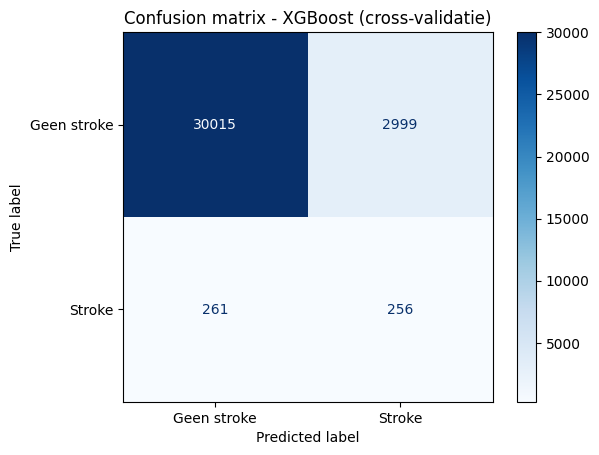

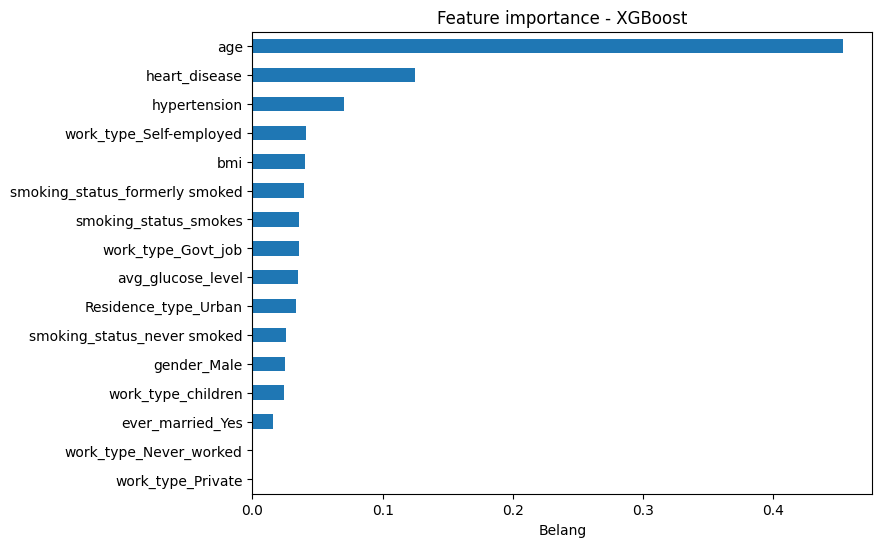

In [73]:
best_xgb = xgb_search.best_estimator_
y_pred_cv = cross_val_predict(best_xgb, X_train, y_train, cv=cv)
ConfusionMatrixDisplay.from_predictions(
    y_train, y_pred_cv, display_labels=["Geen stroke", "Stroke"],
    cmap="Blues", values_format="d")
plt.title("Confusion matrix - XGBoost (cross-validatie)")
plt.show()

best_xgb.fit(X_train, y_train)
xgb_importances = pd.Series(best_xgb.feature_importances_,
                            index=X_train.columns).sort_values()
xgb_importances.plot(kind="barh", figsize=(8, 6))
plt.title("Feature importance - XGBoost")
plt.xlabel("Belang")
plt.show()

**Beste hyperparameters.** 

`learning_rate=0.05`, `max_depth=3`, `n_estimators=100`, `reg_lambda=1` en `scale_pos_weight=20`. Net als bij de beslisboom en Random Forest werkt een weging van 20 het beste.

**F1-score.** 

Met cross-validatie is de F1 0,136. Dat is opvallend genoeg lager dan Random Forest (0,142) en Gradient Boosting (0,142). Het meest geavanceerde model wint hier dus niet. Wij denken dat dit komt doordat de dataset maar 15 kolommen heeft en het meeste signaal in leeftijd zit. Dan heeft XGBoost weinig om zijn extra kracht op te gebruiken.

**Confusion matrix.** 

XGBoost vindt 256 van de 517 stroke-patiënten (recall ongeveer 50%). Dat zijn er meer dan bij alle andere modellen. Daar staan wel 2.999 valse alarmen tegenover. Door `scale_pos_weight` let het model dus vooral op het vinden van zoveel mogelijk stroke-patiënten.

**Feature importance.** 

Leeftijd blijft het belangrijkst (45%), daarna hartziekte (13%) en hoge bloeddruk (7%). Bij XGBoost krijgen hartziekte en hoge bloeddruk meer gewicht dan bij Random Forest. Dat komt doordat XGBoost meet hoeveel een kolom het model verbetert als hij gebruikt wordt, en een kolom als hartziekte geeft dan in één keer een grote verbetering.

### 4.9 Eigen ensemble

#### Uitleg
#### Resultaten

## 5. Conclusie en advies

### 5.1 Overzicht scores

| Model | F1 notebook | F1 Kaggle |
|---|---|---|
| KNN | | |
| Logistic Regression | | |
| SVM | | |
| Decision Tree | | |
| Random Forest | | |
| Gradient Boosting | | |
| XGBoost | | |
| Eigen ensemble | | |

### 5.2 Welk model presteert het beste?

### 5.3 Andere overwegingen

### 5.4 Advies aan artsen

## 6. Referenties

O'Donnell, M. J., Chin, S. L., Rangarajan, S., Xavier, D., Liu, L., Zhang, H., ... Yusuf, S. (2016). Global and regional effects of potentially modifiable risk factors associated with acute stroke in 32 countries (INTERSTROKE): A case-control study. *The Lancet, 388*(10046), 761–775. https://doi.org/10.1016/S0140-6736(16)30506-2

scikit-learn developers. (z.d.). *StandardScaler*. scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
